# PLL Jitter Optimization: Coarse & Fine Sweeps Analysis
**Notebook:** `sw/tools/notebooks/jitter_filter_opt.ipynb`

This notebook analyzes loop filter optimization sweeps from `sw/tests/pll_opt_jitter.py` across **4.8 GHz, 6.0 GHz, 7.0 GHz, and 8.0 GHz**:
- **Adaptive Multi-Tier Support**:
  - Automatically displays **both coarse & fine sweeps**, **only coarse sweeps**, or **only fine sweeps**, depending on the found results or your chosen view mode.
  - **Coarse Sweeps**: Broad parameter exploration around baseline `I=7, R1=7, C1=0, C2=0`.
  - **Fine Sweeps**: Tightly clustered ~10 points around optimal configuration `I=7, R1=7, C1=7, C2=0` (files tagged with `_fine`).
- **Direct Before/After Comparisons**: When both sweeps are available, displays side-by-side tables, overlay spectra, and jitter reduction metrics ($\Delta$ ps and %).
- **Interactive Selectors** (Section 2):
  - **`SELECTED_FREQ`**: Choose active frequency (4.8 GHz, 6.0 GHz, 7.0 GHz, 8.0 GHz).
  - **`SWEEP_TIER_VIEW`**: Select display mode (`'auto'`, `'both'`, `'coarse'`, or `'fine'`).
- **Combined Multi-Frequency Comparison** (Section 11): Cross-frequency benchmark tables, jitter scaling trends, and phase noise overlays.


In [15]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Results directory
PLL_RESULTS_DIR = Path.cwd().resolve().parents[2] / "results" / "pll"

# Styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### 1. Helper Functions for Loading & Analyzing Data (Coarse & Fine Tiers)


In [16]:
class RunSelection(tuple):
    """Container for active frequency run data.
    
    Supports tuple unpacking for backward-compatibility:
        df_results, df_traces, active_path, active_freq = select_run_by_frequency(...)
    and attribute access for adaptive coarse/fine sweeps:
        active_run.coarse, active_run.fine, active_run.has_coarse, active_run.has_fine, etc.
    """
    def __new__(cls, df_results, df_traces, path, freq, coarse=None, fine=None):
        return super().__new__(cls, (df_results, df_traces, path, freq))

    def __init__(self, df_results, df_traces, path, freq, coarse=None, fine=None):
        self.df_results = df_results
        self.df_traces = df_traces
        self.path = path
        self.freq = freq
        self.freq_ghz = freq / 1e9
        self.coarse = coarse
        self.fine = fine
        self.df_coarse = coarse["df"] if coarse else None
        self.traces_coarse = coarse["traces"] if coarse else None
        self.df_fine = fine["df"] if fine else None
        self.traces_fine = fine["traces"] if fine else None

    @property
    def has_coarse(self):
        return self.df_coarse is not None and not self.df_coarse.empty

    @property
    def has_fine(self):
        return self.df_fine is not None and not self.df_fine.empty

    @property
    def has_both(self):
        return self.has_coarse and self.has_fine


def determine_tiers_to_show(active_run, view_mode="auto"):
    """Determine whether to display coarse, fine, or both sweeps based on found results and user view mode.
    
    Args:
        active_run: RunSelection instance.
        view_mode: 'auto' (default: adapt to found results), 'both', 'coarse', or 'fine'.
        
    Returns:
        tuple: (show_coarse: bool, show_fine: bool)
    """
    has_c = active_run.has_coarse
    has_f = active_run.has_fine
    mode = str(view_mode).lower().strip()
    
    if mode == "coarse":
        return True, False
    elif mode == "fine":
        return False, True
    elif mode == "both":
        return True, True
    else:  # 'auto'
        if has_c and has_f:
            return True, True
        elif has_f:
            return False, True
        else:
            return True, False


def parse_freq_key(val):
    """Normalize frequency input (e.g. 4.8e9, 4.8, '4.8GHz', '6GHz') to Hz float."""
    if isinstance(val, (int, float)):
        return float(val) if val > 1e6 else float(val) * 1e9
    s = str(val).lower().replace("ghz", "").replace("hz", "").strip()
    try:
        f = float(s)
        return f if f > 1e6 else f * 1e9
    except ValueError:
        return 4.8e9


def find_latest_results(results_dir=PLL_RESULTS_DIR, prefix="pll_opt_jitter_"):
    """Find the most recent scalar and traces CSV files from an optimization run."""
    candidates = sorted(results_dir.glob(f"{prefix}*.csv"))
    scalar_files = [f for f in candidates if not f.stem.endswith("_traces") and not f.stem.endswith("_spectra")]
    if not scalar_files:
        raise FileNotFoundError(f"No result files matching {prefix}*.csv found in {results_dir}")
    latest_scalar = scalar_files[-1]
    latest_traces = latest_scalar.with_name(latest_scalar.stem + "_traces.csv")
    return latest_scalar, latest_traces


def load_multi_frequency_data(results_dir=PLL_RESULTS_DIR, target_freqs=(4.8e9, 6.0e9, 7.0e9, 8.0e9)):
    """Load optimization results and trace data for all swept frequencies across coarse and fine tiers.
    
    Categorization rule:
      - Filenames containing '_fine' -> Classified as 'fine' sweep
      - All other standard optimization files -> Classified as 'coarse' sweep
      - Prefers complete runs over interrupted ones (e.g. full 16-point run over 3-point run)
      
    Returns:
        runs_data (dict): Mapping target_freq -> {
            'freq_ghz': float,
            'coarse': {'df': DataFrame, 'traces': DataFrame, 'path': Path, 'sweep_tier': 'coarse'},
            'fine': {'df': DataFrame, 'traces': DataFrame, 'path': Path, 'sweep_tier': 'fine'},
            'df': DataFrame (active default),
            'traces': DataFrame (active default),
            'path': Path (active default),
        }
        df_combined (DataFrame): Concatenated results across all frequencies
        df_traces_combined (DataFrame): Concatenated traces across all frequencies
    """
    candidates = sorted(results_dir.glob("pll_opt_jitter_*.csv"), key=lambda p: p.stat().st_mtime, reverse=True)
    scalar_files = [f for f in candidates if not f.stem.endswith("_traces") and not f.stem.endswith("_spectra")]
    
    runs_data = {
        tf: {
            "freq_ghz": tf / 1e9,
            "coarse": None,
            "fine": None,
            "df": None,
            "traces": None,
            "path": None,
        }
        for tf in target_freqs
    }
    
    for f in scalar_files:
        try:
            is_fine = "_fine" in f.stem.lower()
            sweep_tier = "fine" if is_fine else "coarse"

            df = pd.read_csv(f)
            if "f_vco" not in df.columns or df.empty:
                continue

            traces_path = f.with_name(f.stem + "_traces.csv")
            traces_df = pd.read_csv(traces_path) if traces_path.exists() else None

            for tf in target_freqs:
                existing = runs_data[tf][sweep_tier]
                if existing is not None and len(existing["df"]) >= 8:
                    continue  # already have a complete run for this tier & frequency

                matches = df[df["f_vco"].apply(lambda val: abs(val - tf) < 1.0e8)]
                if not matches.empty:
                    if existing is not None and len(matches) <= len(existing["df"]):
                        continue

                    df_sub = matches.copy()
                    df_sub["config_label"] = df_sub.apply(
                        lambda r: f"I={int(r['set_current'])}, R1={int(r['set_r1'])}, C1={int(r['set_c1'])}, C2={int(r['set_c2'])}",
                        axis=1
                    )
                    df_sub["run_idx"] = np.arange(1, len(df_sub) + 1)
                    df_sub["sweep_tier"] = sweep_tier
                    if "pll_p" in df_sub.columns and "pll_p_mw" not in df_sub.columns:
                        df_sub["pll_p_mw"] = df_sub["pll_p"] * 1e3
                    if "pll_i" in df_sub.columns and "pll_i_ma" not in df_sub.columns:
                        df_sub["pll_i_ma"] = df_sub["pll_i"] * 1e3

                    sub_traces = None
                    if traces_df is not None and not traces_df.empty:
                        if "f_vco" in traces_df.columns:
                            match_mask = traces_df["f_vco"].astype(float).between(tf - 1.0e8, tf + 1.0e8)
                            if match_mask.any():
                                sub_traces = traces_df[match_mask].copy()
                        elif "kind" in traces_df.columns:
                            sub_traces = traces_df.copy()

                    entry = {
                        "df": df_sub,
                        "traces": sub_traces,
                        "path": f,
                        "freq_ghz": tf / 1e9,
                        "sweep_tier": sweep_tier,
                    }
                    runs_data[tf][sweep_tier] = entry

                    # Active default: prefer fine if available, else coarse
                    if sweep_tier == "fine" or runs_data[tf]["df"] is None:
                        runs_data[tf]["df"] = df_sub
                        runs_data[tf]["traces"] = sub_traces
                        runs_data[tf]["path"] = f
                        runs_data[tf]["active_tier"] = sweep_tier
        except Exception:
            continue

    print("=" * 80)
    print("  MULTI-FREQUENCY DATA LOADER SUMMARY (Coarse & Fine Sweeps)")
    print("=" * 80)
    for tf in target_freqs:
        f_ghz = tf / 1e9
        entry = runs_data[tf]
        c = entry.get("coarse")
        fn = entry.get("fine")

        c_info = "None"
        if c:
            c_locked = int(c["df"]["locked"].sum()) if "locked" in c["df"].columns else len(c["df"])
            best_c = (c["df"]["time_jitter_pnm_ps"].min() if ("time_jitter_pnm_ps" in c["df"].columns and c["df"]["time_jitter_pnm_ps"].notna().any()) else c["df"].get("time_jitter_trace_ps", pd.Series()).min())
            c_info = f"{len(c['df'])} pts ({c_locked} locked, best: {best_c:.2f} ps)"

        fn_info = "None"
        if fn:
            fn_locked = int(fn["df"]["locked"].sum()) if "locked" in fn["df"].columns else len(fn["df"])
            best_fn = (fn["df"]["time_jitter_pnm_ps"].min() if ("time_jitter_pnm_ps" in fn["df"].columns and fn["df"]["time_jitter_pnm_ps"].notna().any()) else fn["df"].get("time_jitter_trace_ps", pd.Series()).min())
            fn_info = f"{len(fn['df'])} pts ({fn_locked} locked, best: {best_fn:.2f} ps)"

        print(f"  {f_ghz:.1f} GHz -> Coarse: {c_info:<35} | Fine: {fn_info}")
    print("=" * 80)

    combined_dfs = [entry["df"] for entry in runs_data.values() if entry["df"] is not None]
    combined_traces = [entry["traces"] for entry in runs_data.values() if entry["traces"] is not None]
    
    df_combined = pd.concat(combined_dfs, ignore_index=True) if combined_dfs else pd.DataFrame()
    df_traces_combined = pd.concat(combined_traces, ignore_index=True) if combined_traces else pd.DataFrame()
    
    return runs_data, df_combined, df_traces_combined


def select_run_by_frequency(runs_data, freq=4.8e9):
    """Select active run for a frequency.
    
    Returns a RunSelection instance that can be unpacked as 4-tuple:
        df_results, df_traces, active_path, active_freq = select_run_by_frequency(...)
    or accessed with attributes:
        active_run.coarse, active_run.fine, active_run.df_coarse, active_run.df_fine, etc.
    """
    tf = parse_freq_key(freq)
    if tf not in runs_data:
        closest = min(runs_data.keys(), key=lambda k: abs(k - tf))
        tf = closest
    entry = runs_data[tf]
    coarse = entry.get("coarse")
    fine = entry.get("fine")
    
    df_c = coarse["df"] if coarse else None
    tr_c = coarse["traces"] if coarse else None
    df_f = fine["df"] if fine else None
    tr_f = fine["traces"] if fine else None
    
    df_primary = df_f if df_f is not None else df_c
    tr_primary = tr_f if tr_f is not None else tr_c
    active_path = (fine or coarse or {}).get("path")
    
    return RunSelection(df_primary, tr_primary, active_path, tf, coarse=coarse, fine=fine)


def get_best_config(df):
    """Return dictionary with the best configuration details."""
    if df is None or df.empty:
        return {}
    locked = df[df["locked"] == 1] if "locked" in df.columns else df
    target = locked if not locked.empty else df
    if target.empty or "time_jitter_trace_ps" not in target.columns:
        return {}
    best_row = target.loc[target["time_jitter_trace_ps"].idxmin()]
    return {
        "label": best_row["config_label"],
        "jitter_ps": best_row["time_jitter_trace_ps"],
        "noise_ps": best_row.get("time_jitter_noise_ps", float("nan")),
        "spur_ps": best_row.get("time_jitter_spur_ps", float("nan")),
        "ref_spur_dbc": best_row.get("ref_spur_dbc", float("nan")),
        "ref_spur_vco_dbc": best_row.get("ref_spur_vco_dbc", float("nan")),
        "power_mw": best_row.get("pll_p_mw", best_row.get("pll_p", float("nan")) * 1e3),
        "I": int(best_row["set_current"]),
        "R1": int(best_row["set_r1"]),
        "C1": int(best_row["set_c1"]),
        "C2": int(best_row["set_c2"]),
        "row": best_row,
    }


### 2. Load Multi-Frequency Runs & Select Active Frequency
Loads optimization data for all swept frequencies (**4.8 GHz, 6.0 GHz, 7.0 GHz, 8.0 GHz**).

> [!TIP]
> Use the **`SELECTED_FREQ`** variable below to switch between displaying individual frequency runs in **Sections 3 through 10**.
> The **Combined Multi-Frequency Comparison** across all 4 frequencies is presented in **Section 11**.


In [17]:
# Load all available frequency runs (both coarse and fine sweep tiers)
runs_data, df_combined, df_traces_combined = load_multi_frequency_data()

# ==============================================================================
# 1. OPERATING FREQUENCY SELECTOR
# Choose one of: 4.8e9, 6.0e9, 7.0e9, 8.0e9 (or '4.8GHz', '6GHz', '7GHz', '8GHz')
# ==============================================================================
SELECTED_FREQ = 4.8e9

# ==============================================================================
# 2. SWEEP DISPLAY MODE SELECTOR
# Options:
#   'auto'   : Automatically display both if both found, or only coarse/fine if only one found (Default)
#   'both'   : Force displaying both coarse and fine sweeps
#   'coarse' : Force displaying only the coarse sweep
#   'fine'   : Force displaying only the fine sweep
# ==============================================================================
SWEEP_TIER_VIEW = "auto"

# Switch and load active run data
active_run = select_run_by_frequency(runs_data, SELECTED_FREQ)
df_coarse = active_run.df_coarse
traces_coarse = active_run.traces_coarse
df_fine = active_run.df_fine
traces_fine = active_run.traces_fine

has_coarse = active_run.has_coarse
has_fine = active_run.has_fine
show_coarse, show_fine = determine_tiers_to_show(active_run, SWEEP_TIER_VIEW)

# Convenience references for active dataset
df_results = active_run.df_results
df_traces = active_run.df_traces
active_path = active_run.path
active_freq = active_run.freq

mode_desc = (
    "Both Coarse & Fine Sweeps"
    if (show_coarse and show_fine and has_coarse and has_fine)
    else ("Only Fine Sweep" if (show_fine and has_fine) else "Only Coarse Sweep")
)

print(f"\nActive Operating Frequency: {active_run.freq_ghz:.1f} GHz")
print(f"Active Display Mode:        {mode_desc} (Setting: '{SWEEP_TIER_VIEW}')")
if active_run.coarse:
    best_c = get_best_config(df_coarse)
    best_str = f"{best_c['jitter_ps']:.2f} ps ({best_c['label']})" if best_c else "n/a"
    print(f"  • Coarse Sweep: {len(df_coarse)} points ({active_run.coarse['path'].name}) -> Best Jitter: {best_str}")
else:
    print("  • Coarse Sweep: None found")

if active_run.fine:
    best_f = get_best_config(df_fine)
    best_str = f"{best_f['jitter_ps']:.2f} ps ({best_f['label']})" if best_f else "n/a"
    print(f"  • Fine Sweep:   {len(df_fine)} points ({active_run.fine['path'].name}) -> Best Jitter: {best_str}")
else:
    print("  • Fine Sweep:   Not yet measured (run with tag='<freq>_fine' to generate)")


  MULTI-FREQUENCY DATA LOADER SUMMARY (Coarse & Fine Sweeps)
  4.8 GHz -> Coarse: 16 pts (16 locked, best: 15.55 ps)  | Fine: 9 pts (9 locked, best: 15.64 ps)
  6.0 GHz -> Coarse: 16 pts (16 locked, best: 29.53 ps)  | Fine: 9 pts (9 locked, best: 49.86 ps)
  7.0 GHz -> Coarse: 16 pts (16 locked, best: 21.78 ps)  | Fine: 9 pts (9 locked, best: 21.40 ps)
  8.0 GHz -> Coarse: 16 pts (16 locked, best: 18.05 ps)  | Fine: 9 pts (9 locked, best: 17.55 ps)

Active Operating Frequency: 4.8 GHz
Active Display Mode:        Both Coarse & Fine Sweeps (Setting: 'auto')
  • Coarse Sweep: 16 points (pll_opt_jitter_S5_20261105_084335_4.8GHz.csv) -> Best Jitter: 15.85 ps (I=7, R1=7, C1=7, C2=0)
  • Fine Sweep:   9 points (pll_opt_jitter_S5_20261105_105813_4.8GHz_fine.csv) -> Best Jitter: 16.16 ps (I=7, R1=6, C1=7, C2=0)


### 3. Ranked Results Table
Sorts all evaluated configurations by total integrated RMS jitter (`time_jitter_trace_ps`).

#### Explanation of Jitter & Spur Metrics:

##### 1. RMS Timing Jitter Metrics
- **`time_jitter_pnm_ps` (Phase Noise Mode Jitter, FSW K40 - Primary Source of Truth)**: The primary, most accurate integrated RMS time jitter measured directly by the instrument's hardware Phase Noise Mode application over **1 kHz to 20 MHz**. Used as the primary optimization and ranking metric across all sections.
- **`time_jitter_trace_ps` (Total RMS Jitter, Stitched Curve)**: Cross-validation metric computed from our stitched spectrum analyzer phase noise curve $L(f)$ over the full band (**1 kHz to 20 MHz**): The total integrated RMS time jitter computed from our stitched spectrum analyzer phase noise curve $L(f)$ over the full measured band (**1 kHz to 20 MHz**):
  $$\sigma_t = \frac{\sqrt{2 \int 10^{L(f)/10} df}}{2\pi f_c}$$
- **`time_jitter_noise_ps` (Random Noise Component)**: The continuous random noise contribution to jitter. It is calculated by identifying discrete spur peaks in $L(f)$, replacing them with the local noise floor baseline, and integrating the resulting continuous curve $L_{\text{noise}}(f)$.
- **`time_jitter_pnm_ps` (Phase Noise Mode Jitter, FSW K40)**: The residual RMS jitter measured directly by the Rohde & Schwarz FSW Phase Noise Mode application across its tracking band (**1 kHz to 20 MHz**), used to cross-validate our full-curve integration.

*(Note: Because time jitter $\sigma_t = \sigma_\phi / (2\pi f_c)$ is scale-invariant under frequency division, these picosecond values measured on the 75 MHz pad clock are identical to the edge jitter at the 4.8 GHz VCO).*

##### 2. Spur Metrics & Interpretation
The measurement system captures two distinct classes of spurs:

- **In-Band Discrete Phase Noise Spurs (`spurs`, `time_jitter_spur_ps`, `n_spurs`)**:
  - Discrete deterministic tones located within the phase noise integration offset band (**1 kHz to 20 MHz**).
  - Detected when a spectral bin in $L(f)$ exceeds the local median noise floor baseline by a threshold (e.g. 5 dB).
  - These represent low-frequency interference such as mains hum (50/100 Hz harmonics), switching DC-DC converter ripple, and charge pump / divider crosstalk.
  - Their total power is integrated and converted into picoseconds of deterministic timing jitter ($\sigma_{t,\text{spur}}$), where total jitter satisfies:
    $$\sigma_{t,\text{total}}^2 \approx \sigma_{t,\text{noise}}^2 + \sigma_{t,\text{spur}}^2$$

- **Reference Spur on the Output Pad (`ref_spur_dbm`, `ref_spur_dbc`)**:
  - The fundamental reference feedthrough tone located at an offset from the carrier equal to the PLL reference frequency:
    $$f_{\text{ref}} = \frac{f_{\text{VCO}}}{128} \approx 37.5\text{ MHz} \quad (\text{for } f_{\text{VCO}} = 4.8\text{ GHz})$$
    On the divided output pad ($f_{\text{out}} = f_{\text{VCO}} / 64 = 75\text{ MHz}$), these spurs appear as modulation sidebands at $f_{\text{out}} \pm f_{\text{ref}}$ (at 37.5 MHz and 112.5 MHz).
  - Measured in Spectrum mode using a zoomed narrow span (20 kHz) and high-resolution RBW (10 Hz) for maximum sensitivity above the noise floor.
  - **`ref_spur_dbm`**: Absolute peak power of the strongest reference spur sideband measured at the divided output pad (in dBm).
  - **`ref_spur_dbc`**: Reference spur power relative to the pad carrier power:
    $$\text{Spur}_{\text{pad}}\;(\text{dBc}) = P_{\text{spur}}\;(\text{dBm}) - P_{\text{carrier}}\;(\text{dBm})$$
  - Also tracked individually for the upper ($+f_{\text{ref}}$) and lower ($-f_{\text{ref}}$) sidebands: `ref_spur_upper_dbc` and `ref_spur_lower_dbc`.

- **VCO-Referred Reference Spur (`ref_spur_vco_dbc`)**:
  - The output clock on the test pad is divided down by $N = \text{total\_div} = 64$ from the 4.8 GHz VCO.
  - Frequency division by $N$ scales phase modulation sidebands by $1/N$, which attenuates phase noise and spur power relative to the carrier by $20 \log_{10}(N)$:
    $$\mathcal{L}_{\text{pad}}(f) = \mathcal{L}_{\text{VCO}}(f) - 20\log_{10}(N)$$
    For $N = 64$, $20 \log_{10}(64) \approx 36.12\text{ dB}$.
  - Therefore, the reference spur power relative to carrier at the actual 4.8 GHz VCO is $20\log_{10}(N)$ higher than measured on the pad:
    $$\text{Spur}_{\text{VCO}}\;(\text{dBc}) = \text{Spur}_{\text{pad}}\;(\text{dBc}) + 20 \log_{10}(N)$$
    *(Example: a reference spur measured at $-80\text{ dBc}$ on the 75 MHz pad corresponds to $-43.88\text{ dBc}$ at the 4.8 GHz VCO).*


In [18]:
def format_ranked_table(df):
    if df is None or df.empty:
        return pd.DataFrame()
    d = df.copy()
    if "pll_p" in d.columns and "pll_p_mw" not in d.columns:
        d["pll_p_mw"] = d["pll_p"] * 1e3
    if "pll_i" in d.columns and "pll_i_ma" not in d.columns:
        d["pll_i_ma"] = d["pll_i"] * 1e3
    display_cols = [
        "run_idx", "config_label", "set_current", "set_r1", "set_c1", "set_c2",
        "time_jitter_pnm_ps", "time_jitter_trace_ps", "time_jitter_noise_ps", "time_jitter_spur_ps",
        "ref_spur_dbc", "ref_spur_vco_dbc", "ref_spur_dbm",
        "pll_p_mw", "carrier_dbm", "locked"
    ]
    available_cols = [c for c in display_cols if c in d.columns]
    sort_col = "time_jitter_pnm_ps" if ("time_jitter_pnm_ps" in d.columns and d["time_jitter_pnm_ps"].notna().any()) else "time_jitter_trace_ps"
    ranked = d[available_cols].sort_values(sort_col).reset_index(drop=True)
    ranked.index = ranked.index + 1
    ranked.index.name = "Rank"
    return ranked

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

# Adaptive display: Coarse, Fine, or Both
both_active = show_coarse and show_fine and has_coarse and has_fine

if show_coarse and has_coarse:
    tier_tag = " - Coarse Sweep" if both_active else ""
    print(f"=== RANKED RESULTS TABLE: {active_run.freq_ghz:.1f} GHz{tier_tag} ===")
    display(format_ranked_table(df_coarse))

if show_fine and has_fine:
    tier_tag = " - Fine Sweep" if both_active else ""
    print(f"\n=== RANKED RESULTS TABLE: {active_run.freq_ghz:.1f} GHz{tier_tag} ===")
    display(format_ranked_table(df_fine))


=== RANKED RESULTS TABLE: 4.8 GHz - Coarse Sweep ===


,run_idx,config_label,set_current,set_r1,set_c1,set_c2,time_jitter_pnm_ps,time_jitter_trace_ps,time_jitter_noise_ps,time_jitter_spur_ps,ref_spur_dbc,ref_spur_vco_dbc,ref_spur_dbm,pll_p_mw,carrier_dbm,locked
Rank,,,,,,,,,,,,,,,,
1,11,"I=7, R1=7, C1=3, C2=0",7,7,3,0,15.55,16.01,15.99,0.75,-40.99,-4.87,-39.51,0.99,1.49,1
2,12,"I=7, R1=7, C1=7, C2=0",7,7,7,0,15.64,15.85,15.83,0.74,-40.97,-4.85,-39.50,0.99,1.47,1
3,10,"I=7, R1=7, C1=1, C2=0",7,7,1,0,16.29,16.57,16.55,0.75,-40.98,-4.86,-39.52,0.99,1.46,1
4,9,"I=7, R1=7, C1=0, C2=0",7,7,0,0,16.40,17.62,17.61,0.76,-41.03,-4.91,-39.54,0.99,1.49,1
5,4,"I=7, R1=7, C1=0, C2=0",7,7,0,0,16.54,17.55,17.53,0.76,-41.05,-4.92,-39.56,0.99,1.49,1
6,14,"I=7, R1=7, C1=0, C2=1",7,7,0,1,16.98,17.78,17.77,0.74,-41.03,-4.91,-39.57,0.99,1.47,1
7,3,"I=5, R1=7, C1=0, C2=0",5,7,0,0,17.31,17.99,17.98,0.74,-41.14,-5.01,-39.67,0.98,1.47,1
8,13,"I=7, R1=7, C1=0, C2=0",7,7,0,0,17.51,17.83,17.81,0.75,-41.00,-4.88,-39.53,0.99,1.47,1
9,8,"I=7, R1=7, C1=0, C2=0",7,7,0,0,17.61,17.50,17.49,0.75,-41.03,-4.91,-39.54,0.99,1.49,1



=== RANKED RESULTS TABLE: 4.8 GHz - Fine Sweep ===


,run_idx,config_label,set_current,set_r1,set_c1,set_c2,time_jitter_pnm_ps,time_jitter_trace_ps,time_jitter_noise_ps,time_jitter_spur_ps,ref_spur_dbc,ref_spur_vco_dbc,ref_spur_dbm,pll_p_mw,carrier_dbm,locked
Rank,,,,,,,,,,,,,,,,
1,7,"I=7, R1=7, C1=6, C2=0",7,7,6,0,15.64,16.17,16.15,0.73,-40.88,-4.76,-39.42,0.98,1.46,1
2,3,"I=7, R1=7, C1=7, C2=0",7,7,7,0,15.85,16.16,16.15,0.74,-40.88,-4.76,-39.42,0.98,1.46,1
3,4,"I=7, R1=5, C1=7, C2=0",7,5,7,0,15.98,16.35,16.33,0.74,-40.72,-4.59,-39.26,0.98,1.46,1
4,6,"I=7, R1=7, C1=5, C2=0",7,7,5,0,16.02,16.16,16.15,0.75,-40.88,-4.76,-39.43,0.98,1.45,1
5,8,"I=7, R1=7, C1=7, C2=1",7,7,7,1,16.10,16.59,16.58,0.72,-40.92,-4.79,-39.46,0.98,1.46,1
6,5,"I=7, R1=6, C1=7, C2=0",7,6,7,0,16.20,16.16,16.15,0.73,-40.80,-4.68,-39.35,0.98,1.45,1
7,9,"I=7, R1=7, C1=7, C2=2",7,7,7,2,16.55,16.60,16.59,0.73,-40.90,-4.78,-39.45,0.98,1.46,1
8,2,"I=6, R1=7, C1=7, C2=0",6,7,7,0,16.74,16.98,16.96,0.76,-41.03,-4.91,-39.59,0.97,1.44,1
9,1,"I=5, R1=7, C1=7, C2=0",5,7,7,0,16.87,17.06,17.04,0.76,-40.98,-4.85,-39.53,0.97,1.45,1


### 4. Jitter Comparison Across Configurations
Compares Total RMS jitter, Random Noise contribution, and Spur contribution across all runs.


/tmp/ipykernel_3692545/1534057118.py:32: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/users/micas/iramrezl/python_venvs/micas_tools_0.1/lib64/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


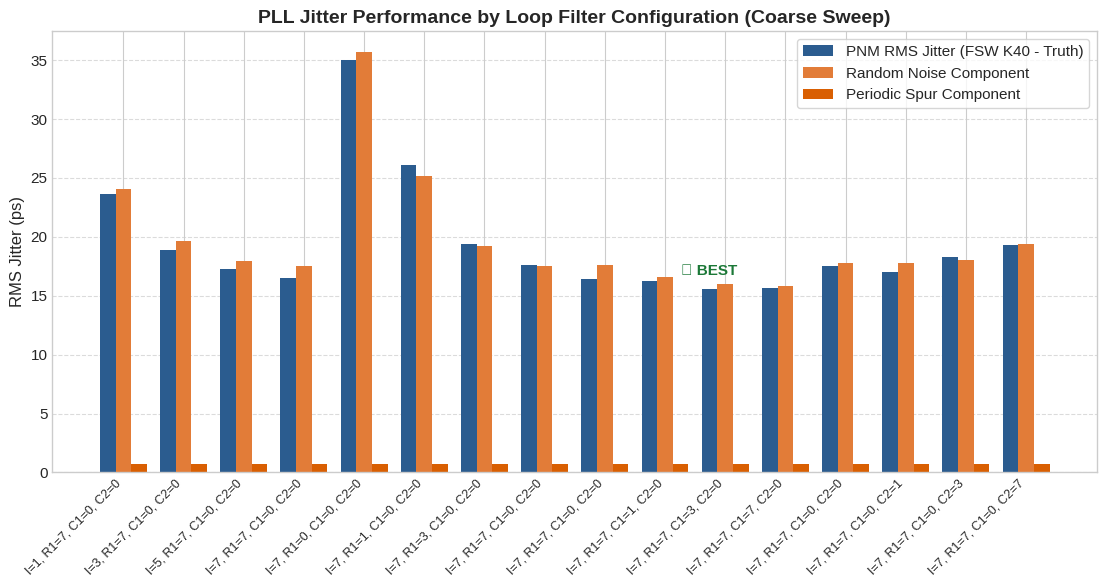

/tmp/ipykernel_3692545/1534057118.py:72: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/users/micas/iramrezl/python_venvs/micas_tools_0.1/lib64/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


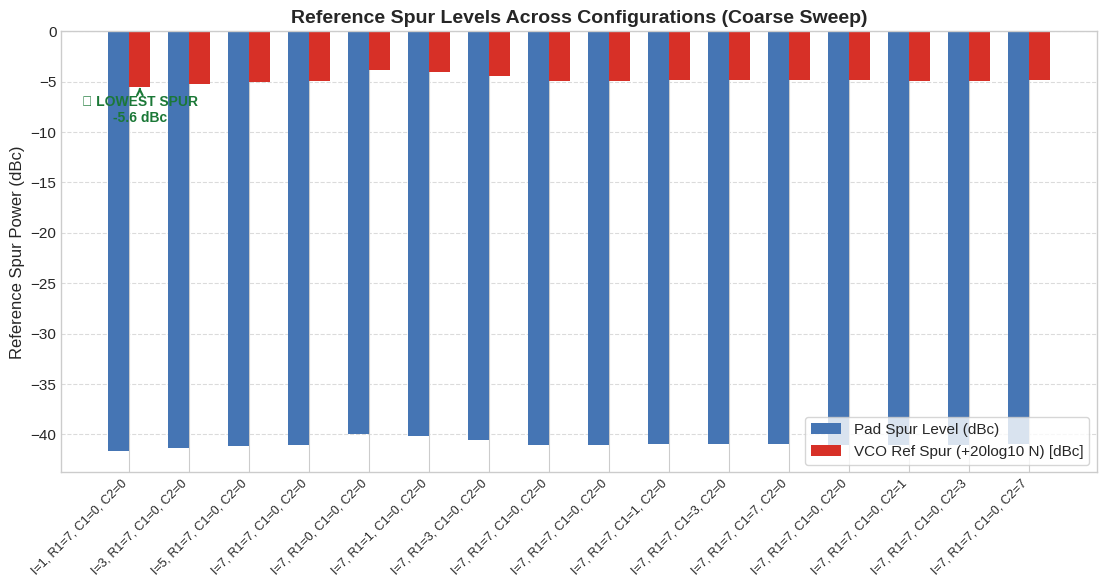

/tmp/ipykernel_3692545/1534057118.py:32: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/users/micas/iramrezl/python_venvs/micas_tools_0.1/lib64/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


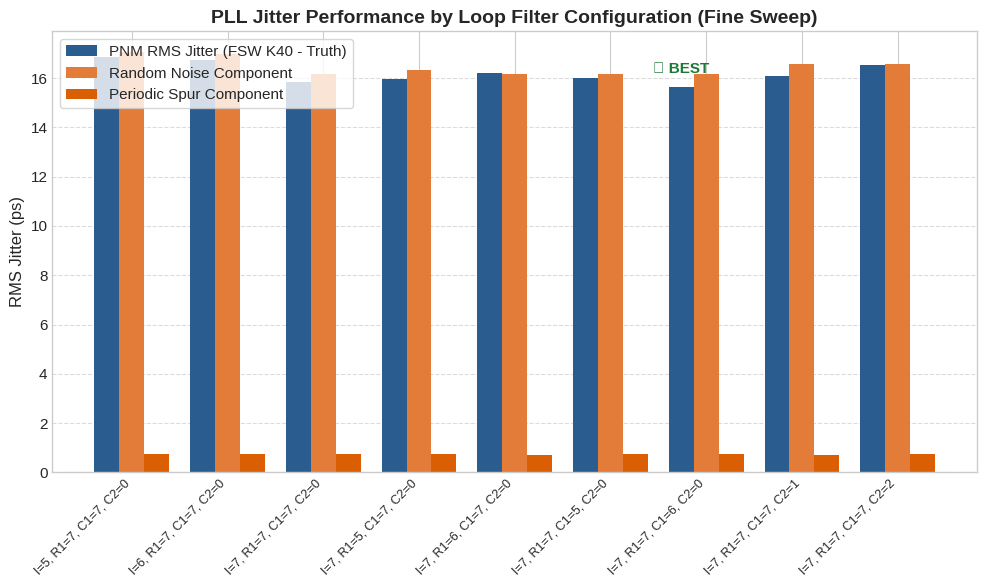

/tmp/ipykernel_3692545/1534057118.py:72: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
  plt.tight_layout()
/users/micas/iramrezl/python_venvs/micas_tools_0.1/lib64/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Liberation Sans.
  fig.canvas.print_figure(bytes_io, **kw)


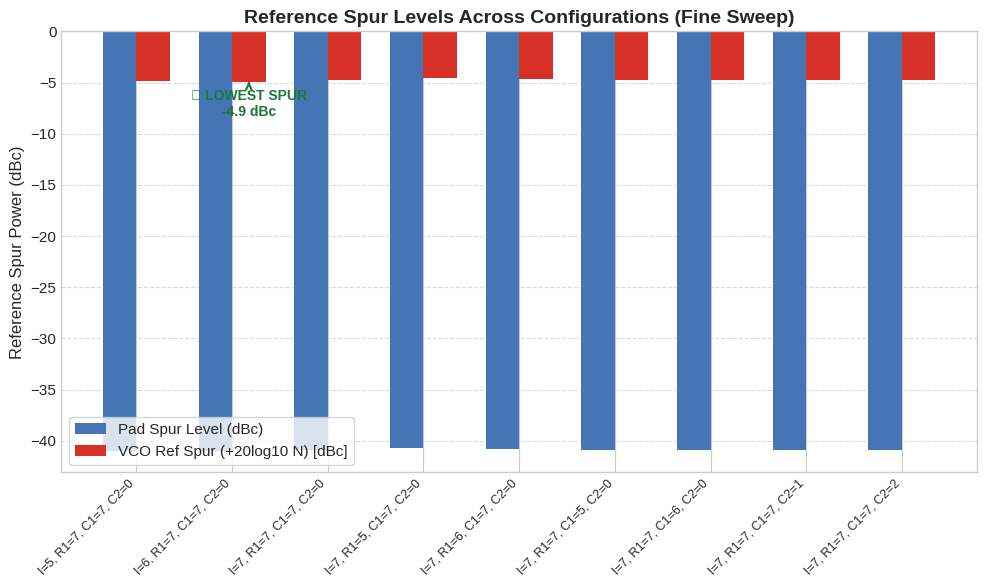

In [19]:
def plot_jitter_comparison_bar(df, metric=None, sort=False, title_suffix=""):
    if df is None or df.empty:
        return
    primary_metric = "time_jitter_pnm_ps" if ("time_jitter_pnm_ps" in df.columns and df["time_jitter_pnm_ps"].notna().any()) else "time_jitter_trace_ps"
    sort_metric = metric if (metric and metric in df.columns) else primary_metric
    data = df.sort_values(sort_metric) if sort else df
    x = np.arange(len(data))
    width = 0.26
    
    fig, ax = plt.subplots(figsize=(max(10, len(data) * 0.7), 6))
    main_lbl = "PNM RMS Jitter (FSW K40 - Truth)" if primary_metric == "time_jitter_pnm_ps" else "Total RMS Jitter"
    rects1 = ax.bar(x - width, data[primary_metric], width, label=main_lbl, color="#2b5c8f")
    rects2 = ax.bar(x, data["time_jitter_noise_ps"], width, label="Random Noise Component", color="#e27c38")
    rects3 = ax.bar(x + width, data["time_jitter_spur_ps"], width, label="Periodic Spur Component", color="#d95f02")
    
    valid_data = data[data[primary_metric].notna()]
    if not valid_data.empty:
        best_idx = valid_data[primary_metric].idxmin()
        best_pos = data.index.get_loc(best_idx)
        ax.annotate(
            "★ BEST", 
            xy=(best_pos - width, data.loc[best_idx, primary_metric]),
            xytext=(0, 10), textcoords="offset points", ha="center", fontweight="bold", color="#1b7837", fontsize=11
        )
    
    ax.set_ylabel("RMS Jitter (ps)", fontsize=12)
    ax.set_title(f"PLL Jitter Performance by Loop Filter Configuration{title_suffix}", fontsize=14, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(data["config_label"], rotation=45, ha="right", fontsize=9)
    ax.legend(frameon=True)
    ax.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.show()


def plot_ref_spur_comparison_bar(df, sort_by=None, title_suffix=""):
    """Compares Reference Spur levels (Pad dBc and VCO dBc) across configurations."""
    if df is None or df.empty or "ref_spur_dbc" not in df.columns or df["ref_spur_dbc"].isna().all():
        return
        
    data = df.sort_values(sort_by) if sort_by else df
    valid_data = data[data["ref_spur_dbc"].notna()].copy()
    if valid_data.empty:
        return

    x = np.arange(len(valid_data))
    width = 0.35
    
    fig, ax = plt.subplots(figsize=(max(10, len(valid_data) * 0.7), 6))
    rects1 = ax.bar(x - width/2, valid_data["ref_spur_dbc"], width, label="Pad Spur Level (dBc)", color="#4575b4")
    if "ref_spur_vco_dbc" in valid_data.columns:
        rects2 = ax.bar(x + width/2, valid_data["ref_spur_vco_dbc"], width, label="VCO Ref Spur (+20log10 N) [dBc]", color="#d73027")
    
    metric_col = "ref_spur_vco_dbc" if "ref_spur_vco_dbc" in valid_data.columns else "ref_spur_dbc"
    best_idx = valid_data[metric_col].idxmin()
    best_pos = valid_data.index.get_loc(best_idx)
    best_val = valid_data.loc[best_idx, metric_col]
    ax.annotate(
        f"★ LOWEST SPUR\n{best_val:.1f} dBc", 
        xy=(best_pos + width/2, best_val),
        xytext=(0, -25 if best_val < 0 else 10), textcoords="offset points",
        ha="center", fontweight="bold", color="#1b7837", fontsize=10,
        arrowprops=dict(arrowstyle="->", color="#1b7837", lw=1.5)
    )
    
    ax.set_ylabel("Reference Spur Power (dBc)", fontsize=12)
    ax.set_title(f"Reference Spur Levels Across Configurations{title_suffix}", fontsize=14, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(valid_data["config_label"], rotation=45, ha="right", fontsize=9)
    ax.legend(frameon=True)
    ax.grid(axis="y", linestyle="--", alpha=0.7)
    plt.tight_layout()
    plt.show()

# Adaptive plotting: Coarse, Fine, or Both
both_active = show_coarse and show_fine and has_coarse and has_fine

if show_coarse and has_coarse:
    suffix = " (Coarse Sweep)" if both_active else ""
    plot_jitter_comparison_bar(df_coarse, title_suffix=suffix)
    plot_ref_spur_comparison_bar(df_coarse, title_suffix=suffix)

if show_fine and has_fine:
    suffix = " (Fine Sweep)" if both_active else ""
    plot_jitter_comparison_bar(df_fine, title_suffix=suffix)
    plot_ref_spur_comparison_bar(df_fine, title_suffix=suffix)


### 5. Loop Filter Parameter Sweep Trends
Shows the sensitivity and trajectory of jitter when varying $I_{CP}$, $R_1$, $C_1$, and $C_2$.


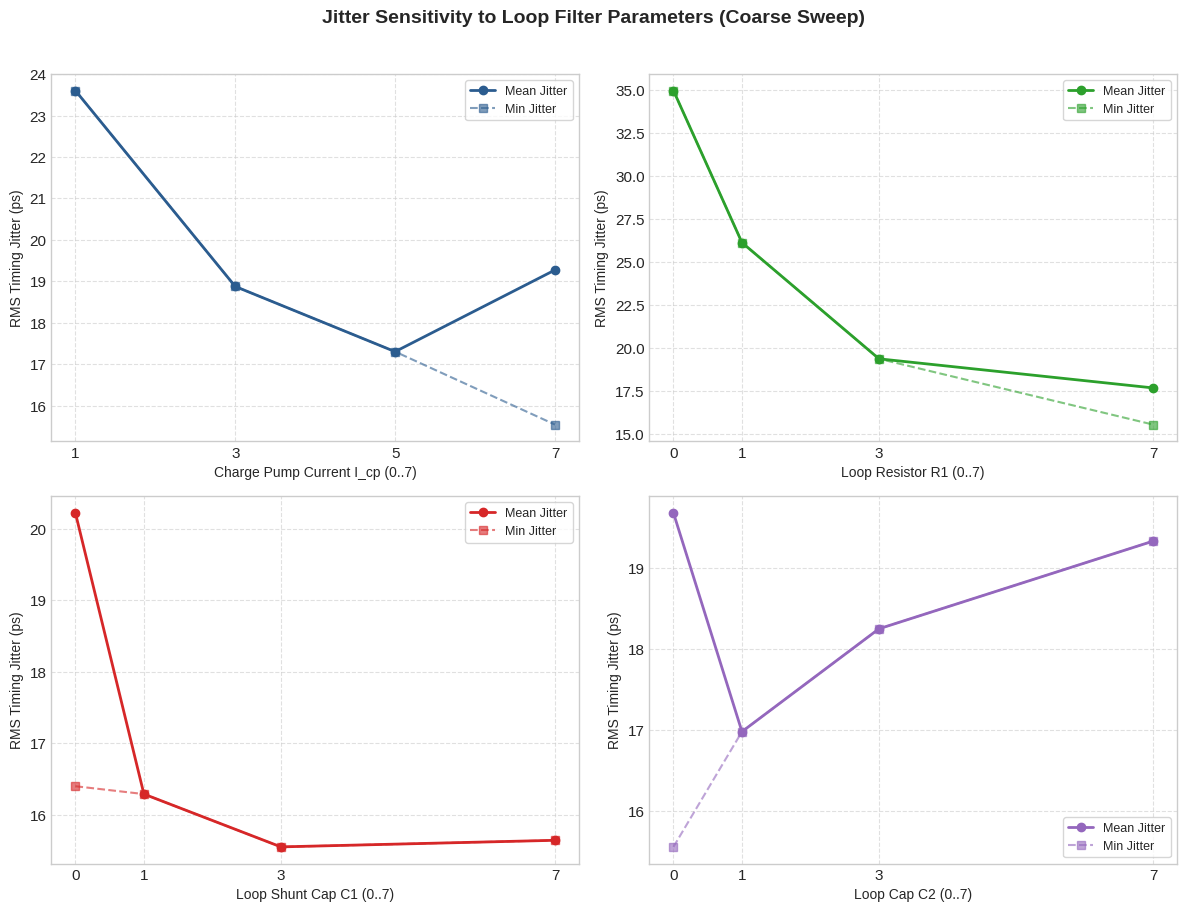

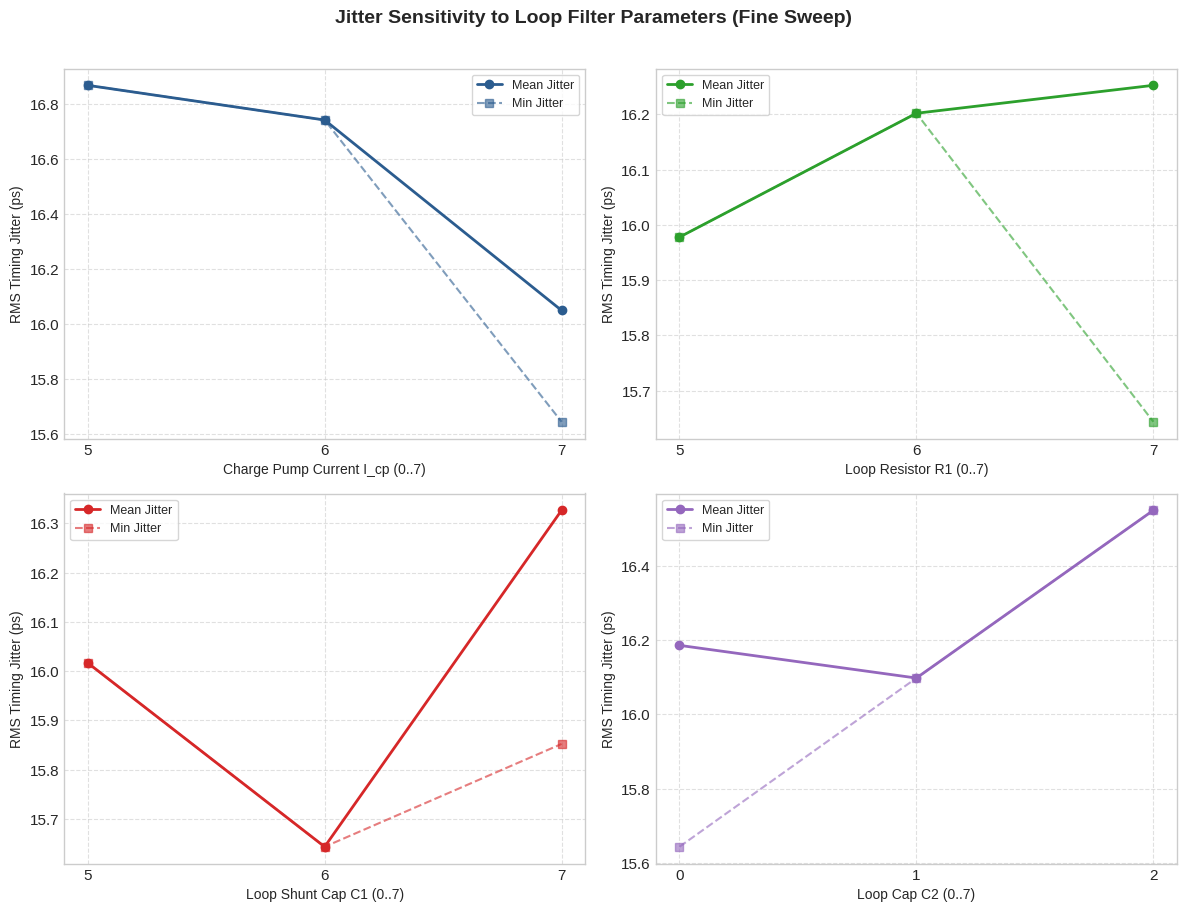

In [20]:
def plot_parameter_trends(df, metric=None, title_suffix=""):
    if df is None or df.empty:
        return
    if metric is None:
        metric = "time_jitter_pnm_ps" if ("time_jitter_pnm_ps" in df.columns and df["time_jitter_pnm_ps"].notna().any()) else "time_jitter_trace_ps"
    if df is None or df.empty:
        return
    params = [
        ("set_current", "Charge Pump Current I_cp (0..7)", "#2b5c8f"),
        ("set_r1", "Loop Resistor R1 (0..7)", "#2ca02c"),
        ("set_c1", "Loop Shunt Cap C1 (0..7)", "#d62728"),
        ("set_c2", "Loop Cap C2 (0..7)", "#9467bd"),
    ]
    fig, axs = plt.subplots(2, 2, figsize=(12, 9))
    axs = axs.ravel()
    
    for i, (col, label, color) in enumerate(params):
        ax = axs[i]
        if col in df.columns:
            means = df.groupby(col)[metric].mean()
            mins = df.groupby(col)[metric].min()
            vals = means.index.values
            ax.plot(vals, means.values, "o-", color=color, linewidth=2, label="Mean Jitter")
            ax.plot(vals, mins.values, "s--", color=color, alpha=0.6, label="Min Jitter")
            ax.set_xlabel(label, fontsize=10)
            ax.set_ylabel("RMS Timing Jitter (ps)", fontsize=10)
            ax.grid(True, linestyle="--", alpha=0.6)
            ax.legend(frameon=True, fontsize=9)
            ax.set_xticks(vals)
            
    plt.suptitle(f"Jitter Sensitivity to Loop Filter Parameters{title_suffix}", fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

# Adaptive plotting: Coarse, Fine, or Both
both_active = show_coarse and show_fine and has_coarse and has_fine

if show_coarse and has_coarse:
    suffix = " (Coarse Sweep)" if both_active else ""
    plot_parameter_trends(df_coarse, title_suffix=suffix)

if show_fine and has_fine:
    suffix = " (Fine Sweep)" if both_active else ""
    plot_parameter_trends(df_fine, title_suffix=suffix)


### 6. Phase Noise Spectra ($L(f)$)
Plots the full phase noise profiles (`L_trace` or Phase Noise mode `L_pnmode`) on the pad or referred to the VCO.


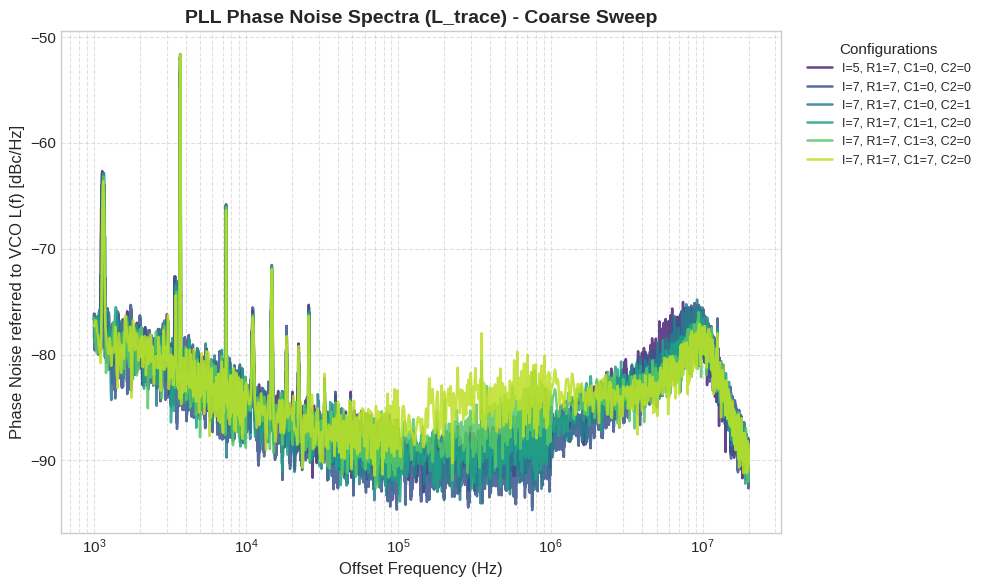

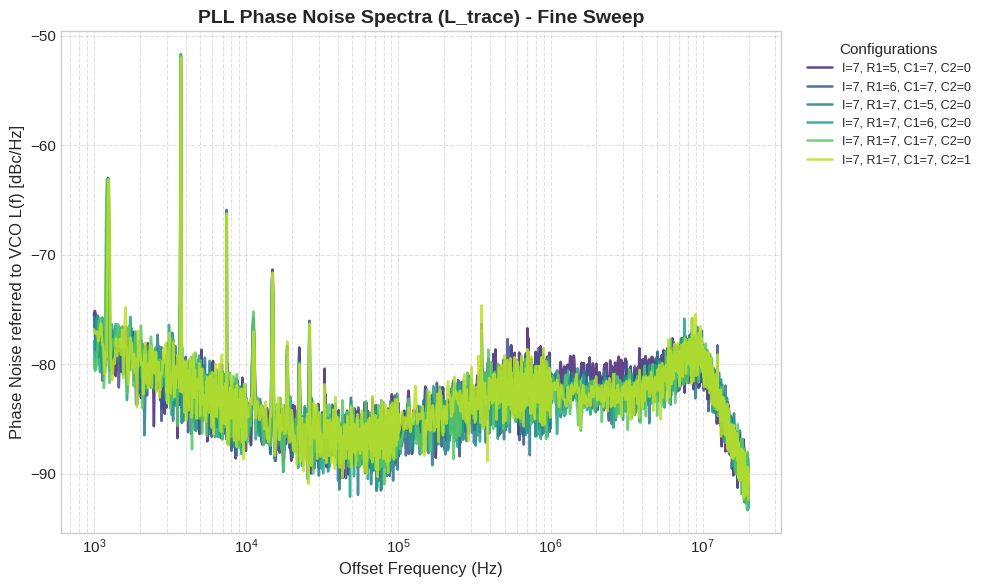

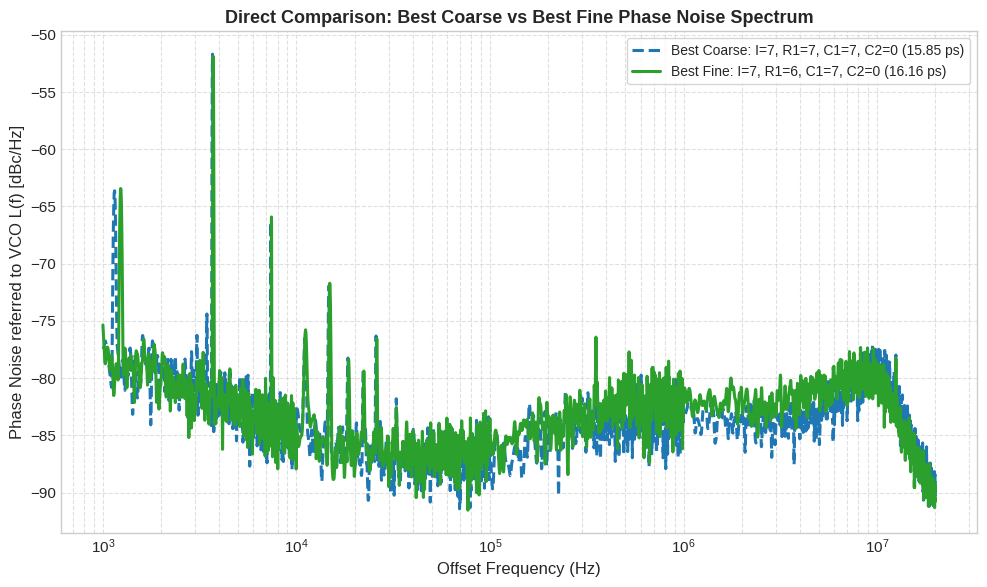

In [21]:
def plot_phase_noise_curves(df_traces, df_results=None, top_n=6, kind="L_trace", ref_to_vco=True, title_suffix=""):
    if df_traces is None or df_traces.empty or "kind" not in df_traces.columns or kind not in df_traces["kind"].values:
        return
        
    sub = df_traces[df_traces["kind"] == kind].copy()
    if df_results is not None:
        jit_sort = "time_jitter_pnm_ps" if ("time_jitter_pnm_ps" in df_results.columns and df_results["time_jitter_pnm_ps"].notna().any()) else "time_jitter_trace_ps"
        best_cfgs = list(df_results.sort_values(jit_sort)["config_label"].unique()[:top_n])
    else:
        best_cfgs = None
        
    group_cols = ["set_current", "set_r1", "set_c1", "set_c2"]
    groups = list(sub.groupby(group_cols))
    if best_cfgs is not None:
        groups = [(vals, grp) for vals, grp in groups if f"I={int(vals[0])}, R1={int(vals[1])}, C1={int(vals[2])}, C2={int(vals[3])}" in best_cfgs]
    groups = groups[:top_n]
    
    if not groups:
        return

    div_db = 20 * math.log10(64) if ref_to_vco else 0.0
    if df_results is not None and "total_div" in df_results.columns:
        div_db = 20 * math.log10(df_results["total_div"].iloc[0]) if ref_to_vco else 0.0
        
    fig, ax = plt.subplots(figsize=(10, 6))
    colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(groups)))
    
    for (vals, grp), color in zip(groups, colors):
        lbl = f"I={int(vals[0])}, R1={int(vals[1])}, C1={int(vals[2])}, C2={int(vals[3])}"
        grp_s = grp.sort_values("freq")
        y_vals = grp_s["level_dbm"] + div_db
        ax.plot(grp_s["freq"], y_vals, label=lbl, color=color, linewidth=1.8, alpha=0.85)
        
    ax.set_xscale("log")
    ax.set_xlabel("Offset Frequency (Hz)", fontsize=12)
    ylabel = "Phase Noise referred to VCO L(f) [dBc/Hz]" if ref_to_vco else "Phase Noise on Pad L(f) [dBc/Hz]"
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title(f"PLL Phase Noise Spectra ({kind}){title_suffix}", fontsize=14, fontweight="bold")
    ax.grid(True, which="both", linestyle="--", alpha=0.6)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Configurations", fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_coarse_vs_fine_best_phase_noise(traces_c, df_c, traces_f, df_f, ref_to_vco=True):
    """Overlay comparing best configuration of coarse sweep against best of fine sweep."""
    if (traces_c is None or traces_c.empty or "kind" not in traces_c.columns or
        traces_f is None or traces_f.empty or "kind" not in traces_f.columns):
        return
    best_c = get_best_config(df_c)
    best_f = get_best_config(df_f)
    if not best_c or not best_f:
        return
    
    fig, ax = plt.subplots(figsize=(10, 6))
    for sweep_name, traces, best, col, ls in [
        ("Best Coarse", traces_c, best_c, "#1f77b4", "--"),
        ("Best Fine", traces_f, best_f, "#2ca02c", "-"),
    ]:
        sub = traces[traces["kind"] == "L_trace"].copy()
        grp = sub[
            (sub["set_current"] == best["I"]) &
            (sub["set_r1"] == best["R1"]) &
            (sub["set_c1"] == best["C1"]) &
            (sub["set_c2"] == best["C2"])
        ].sort_values("freq")
        if grp.empty:
            continue
        div_db = 20 * math.log10(best["row"].get("total_div", 64)) if ref_to_vco else 0.0
        lbl = f"{sweep_name}: {best['label']} ({best['jitter_ps']:.2f} ps)"
        ax.plot(grp["freq"], grp["level_dbm"] + div_db, label=lbl, color=col, linestyle=ls, linewidth=2.2)

    ax.set_xscale("log")
    ax.set_xlabel("Offset Frequency (Hz)", fontsize=12)
    ylabel = "Phase Noise referred to VCO L(f) [dBc/Hz]" if ref_to_vco else "Phase Noise on Pad L(f) [dBc/Hz]"
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title("Direct Comparison: Best Coarse vs Best Fine Phase Noise Spectrum", fontsize=13, fontweight="bold")
    ax.grid(True, which="both", linestyle="--", alpha=0.6)
    ax.legend(frameon=True, fontsize=10)
    plt.tight_layout()
    plt.show()

# Adaptive plotting: Coarse, Fine, or Both
both_active = show_coarse and show_fine and has_coarse and has_fine

if show_coarse and has_coarse:
    suffix = " - Coarse Sweep" if both_active else ""
    plot_phase_noise_curves(traces_coarse, df_coarse, top_n=6, kind="L_trace", ref_to_vco=True, title_suffix=suffix)

if show_fine and has_fine:
    suffix = " - Fine Sweep" if both_active else ""
    plot_phase_noise_curves(traces_fine, df_fine, top_n=6, kind="L_trace", ref_to_vco=True, title_suffix=suffix)

if both_active:
    plot_coarse_vs_fine_best_phase_noise(traces_coarse, df_coarse, traces_fine, df_fine, ref_to_vco=True)


### 7. Interactive Phase Noise Explorer (Plotly)
Hover over curves to read exact offset frequency and noise power; click legend items to isolate specific configurations.


In [22]:
def plot_interactive_phase_noise(df_traces, df_results, kind="L_trace", top_n=8, title_suffix=""):
    if df_traces is None or df_traces.empty or "kind" not in df_traces.columns or kind not in df_traces["kind"].values:
        return
        
    sub = df_traces[df_traces["kind"] == kind].copy()
    locked = df_results[df_results["locked"] == 1] if "locked" in df_results.columns else df_results
    jit_sort = "time_jitter_pnm_ps" if ("time_jitter_pnm_ps" in locked.columns and locked["time_jitter_pnm_ps"].notna().any()) else "time_jitter_trace_ps"
    best_rows = locked.sort_values(jit_sort).head(top_n)
    
    div_db = 20 * math.log10(df_results["total_div"].iloc[0]) if "total_div" in df_results.columns else 0.0
    fig = go.Figure()
    
    for _, row in best_rows.iterrows():
        j_val = row[jit_sort]
        lbl = f"{row['config_label']} ({j_val:.2f} ps PNM)" if jit_sort == "time_jitter_pnm_ps" else f"{row['config_label']} ({j_val:.2f} ps)"
        match = sub[
            (sub["set_current"] == row["set_current"]) &
            (sub["set_r1"] == row["set_r1"]) &
            (sub["set_c1"] == row["set_c1"]) &
            (sub["set_c2"] == row["set_c2"])
        ].sort_values("freq")
        
        if not match.empty:
            fig.add_trace(go.Scatter(
                x=match["freq"],
                y=match["level_dbm"] + div_db,
                mode="lines",
                name=lbl,
                line=dict(width=2)
            ))
            
    fig.update_layout(
        title=f"<b>Interactive Phase Noise Profile (referred to VCO){title_suffix}</b>",
        xaxis=dict(title="Offset Frequency (Hz)", type="log"),
        yaxis=dict(title="L(f) referred to VCO (dBc/Hz)"),
        hovermode="x unified",
        template="plotly_white",
        width=950,
        height=550,
        legend=dict(title="Configurations (Jitter)", yanchor="top", y=0.99, xanchor="left", x=1.02),
    )
    fig.show()

# Adaptive plotting: Coarse, Fine, or Both
both_active = show_coarse and show_fine and has_coarse and has_fine

if show_coarse and has_coarse:
    suffix = " - Coarse Sweep" if both_active else ""
    plot_interactive_phase_noise(traces_coarse, df_coarse, kind="L_trace", top_n=8, title_suffix=suffix)

if show_fine and has_fine:
    suffix = " - Fine Sweep" if both_active else ""
    plot_interactive_phase_noise(traces_fine, df_fine, kind="L_trace", top_n=8, title_suffix=suffix)


### 8. Multi-Panel Performance Dashboard
Comprehensive 4-panel overview summarizing Jitter, Phase Noise, Power, and Spurs.


/tmp/ipykernel_3692545/2357342525.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1, 1].set_xticklabels(top6["config_label"], rotation=30, ha="right", fontsize=9)


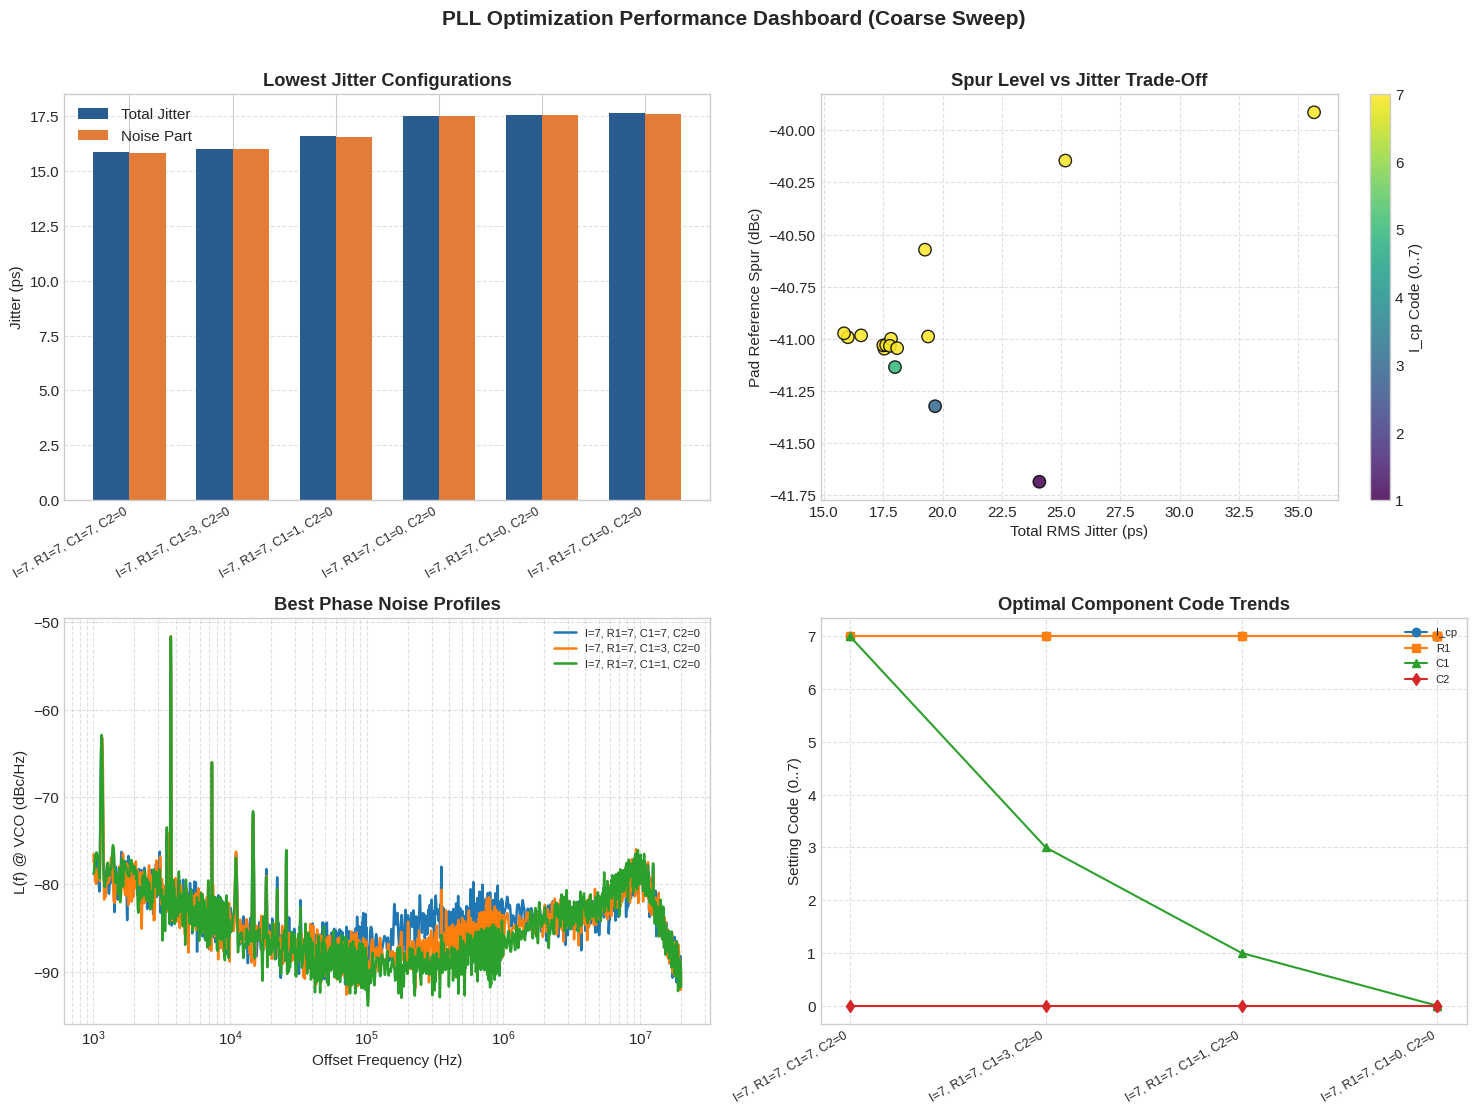

/tmp/ipykernel_3692545/2357342525.py:64: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1, 1].set_xticklabels(top6["config_label"], rotation=30, ha="right", fontsize=9)


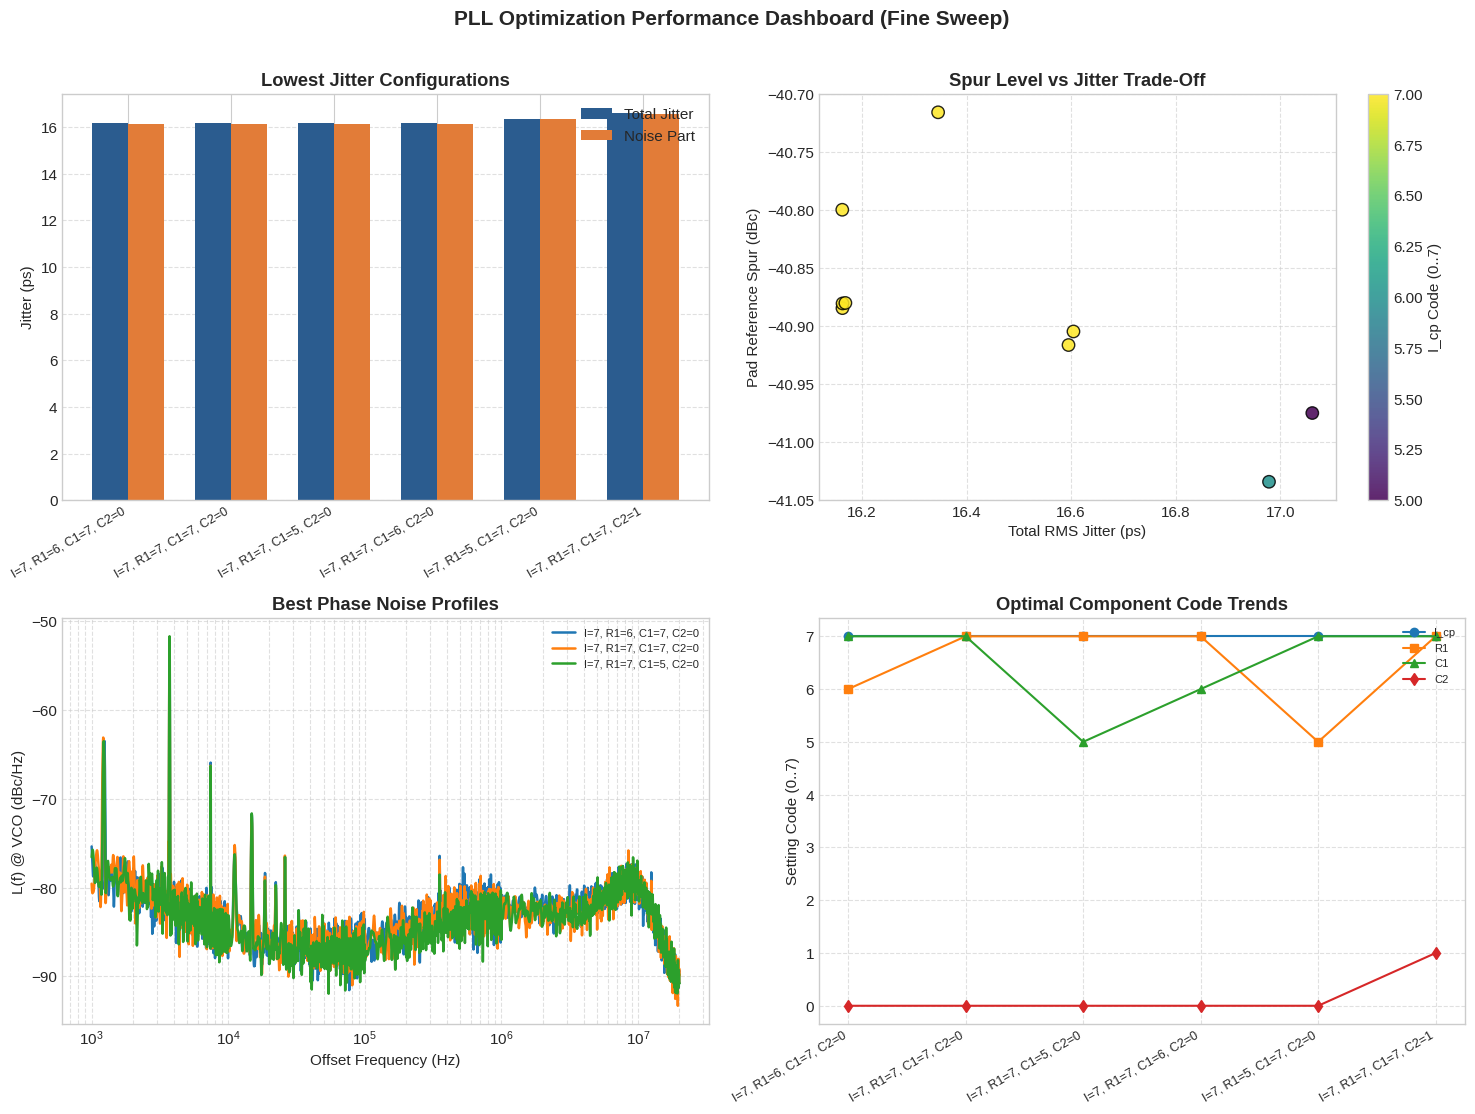

In [23]:
def plot_pll_opt_dashboard(df_results, df_traces, title_suffix=""):
    if df_results is None or df_results.empty:
        return
        
    fig, axs = plt.subplots(2, 2, figsize=(15, 11))
    
    # 1. Jitter Bar Chart (Top 6 configs)
    top6 = df_results.sort_values("time_jitter_trace_ps").head(6)
    x = np.arange(len(top6))
    w = 0.35
    axs[0, 0].bar(x - w/2, top6["time_jitter_trace_ps"], w, label="Total Jitter", color="#2b5c8f")
    axs[0, 0].bar(x + w/2, top6["time_jitter_noise_ps"], w, label="Noise Part", color="#e27c38")
    axs[0, 0].set_xticks(x)
    axs[0, 0].set_xticklabels(top6["config_label"], rotation=30, ha="right", fontsize=9)
    axs[0, 0].set_ylabel("Jitter (ps)")
    axs[0, 0].set_title("Lowest Jitter Configurations", fontweight="bold")
    axs[0, 0].grid(axis="y", linestyle="--", alpha=0.6)
    axs[0, 0].legend()
    
    # 2. Reference Spur vs Jitter Scatter
    if "ref_spur_dbc" in df_results.columns and df_results["ref_spur_dbc"].notna().any():
        sc = axs[0, 1].scatter(df_results["time_jitter_trace_ps"], df_results["ref_spur_dbc"], 
                               c=df_results["set_current"], cmap="viridis", s=80, edgecolors="k", alpha=0.85)
        plt.colorbar(sc, ax=axs[0, 1], label="I_cp Code (0..7)")
        axs[0, 1].set_xlabel("Total RMS Jitter (ps)")
        axs[0, 1].set_ylabel("Pad Reference Spur (dBc)")
        axs[0, 1].set_title("Spur Level vs Jitter Trade-Off", fontweight="bold")
        axs[0, 1].grid(True, linestyle="--", alpha=0.6)
    else:
        pwr = df_results["pll_p_mw"] if "pll_p_mw" in df_results.columns else df_results.get("pll_p", 0) * 1e3
        axs[0, 1].scatter(pwr, df_results["time_jitter_trace_ps"], c="#2ca02c", s=80, edgecolors="k", alpha=0.85)
        axs[0, 1].set_xlabel("PLL Power (mW)")
        axs[0, 1].set_ylabel("Total RMS Jitter (ps)")
        axs[0, 1].set_title("Jitter vs Power Consumption", fontweight="bold")
        axs[0, 1].grid(True, linestyle="--", alpha=0.6)
        
    # 3. Phase Noise Spectra of Best 3
    if df_traces is not None and not df_traces.empty and "kind" in df_traces.columns and "L_trace" in df_traces["kind"].values:
        sub = df_traces[df_traces["kind"] == "L_trace"]
        div_db = 20 * math.log10(df_results["total_div"].iloc[0]) if "total_div" in df_results.columns else 0.0
        for idx, row in top6.head(3).iterrows():
            match = sub[
                (sub["set_current"] == row["set_current"]) &
                (sub["set_r1"] == row["set_r1"]) &
                (sub["set_c1"] == row["set_c1"]) &
                (sub["set_c2"] == row["set_c2"])
            ].sort_values("freq")
            if not match.empty:
                axs[1, 0].plot(match["freq"], match["level_dbm"] + div_db, label=row["config_label"], linewidth=1.8)
        axs[1, 0].set_xscale("log")
        axs[1, 0].set_xlabel("Offset Frequency (Hz)")
        axs[1, 0].set_ylabel("L(f) @ VCO (dBc/Hz)")
        axs[1, 0].set_title("Best Phase Noise Profiles", fontweight="bold")
        axs[1, 0].grid(True, which="both", linestyle="--", alpha=0.6)
        axs[1, 0].legend(fontsize=8)
        
    # 4. Filter Component Trajectory
    axs[1, 1].plot(top6["config_label"], top6["set_current"], "o-", label="I_cp", linewidth=1.5)
    axs[1, 1].plot(top6["config_label"], top6["set_r1"], "s-", label="R1", linewidth=1.5)
    axs[1, 1].plot(top6["config_label"], top6["set_c1"], "^-", label="C1", linewidth=1.5)
    axs[1, 1].plot(top6["config_label"], top6["set_c2"], "d-", label="C2", linewidth=1.5)
    axs[1, 1].set_ylabel("Setting Code (0..7)")
    axs[1, 1].set_title("Optimal Component Code Trends", fontweight="bold")
    axs[1, 1].set_xticklabels(top6["config_label"], rotation=30, ha="right", fontsize=9)
    axs[1, 1].grid(True, linestyle="--", alpha=0.6)
    axs[1, 1].legend(loc="upper right", fontsize=8)
    
    plt.suptitle(f"PLL Optimization Performance Dashboard{title_suffix}", fontsize=15, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

# Adaptive plotting: Coarse, Fine, or Both
both_active = show_coarse and show_fine and has_coarse and has_fine

if show_coarse and has_coarse:
    suffix = " (Coarse Sweep)" if both_active else ""
    plot_pll_opt_dashboard(df_coarse, traces_coarse, title_suffix=suffix)

if show_fine and has_fine:
    suffix = " (Fine Sweep)" if both_active else ""
    plot_pll_opt_dashboard(df_fine, traces_fine, title_suffix=suffix)


### 9. Output Pad RF Spectra (Around Carrier)
Plots the averaged output carrier and skirts.


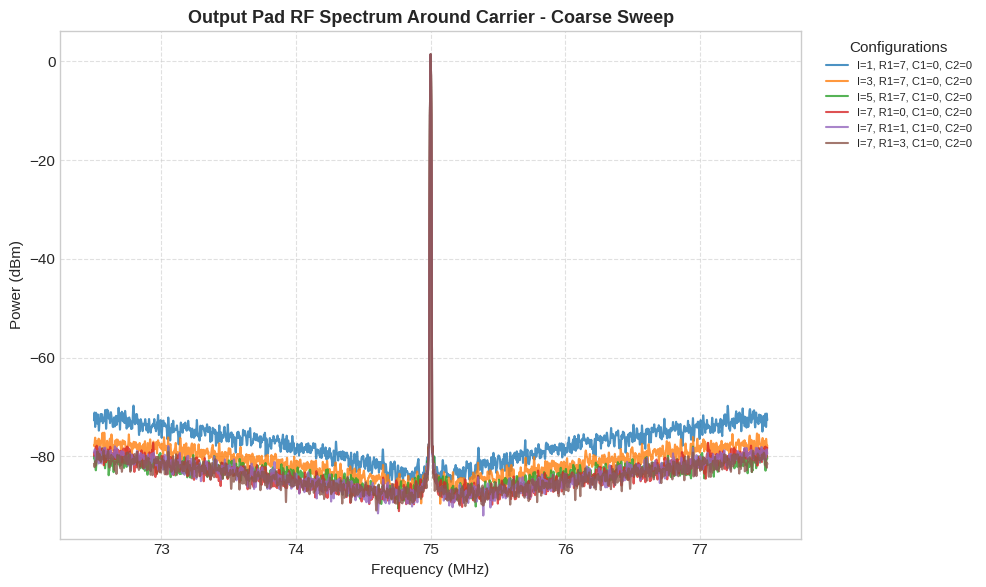

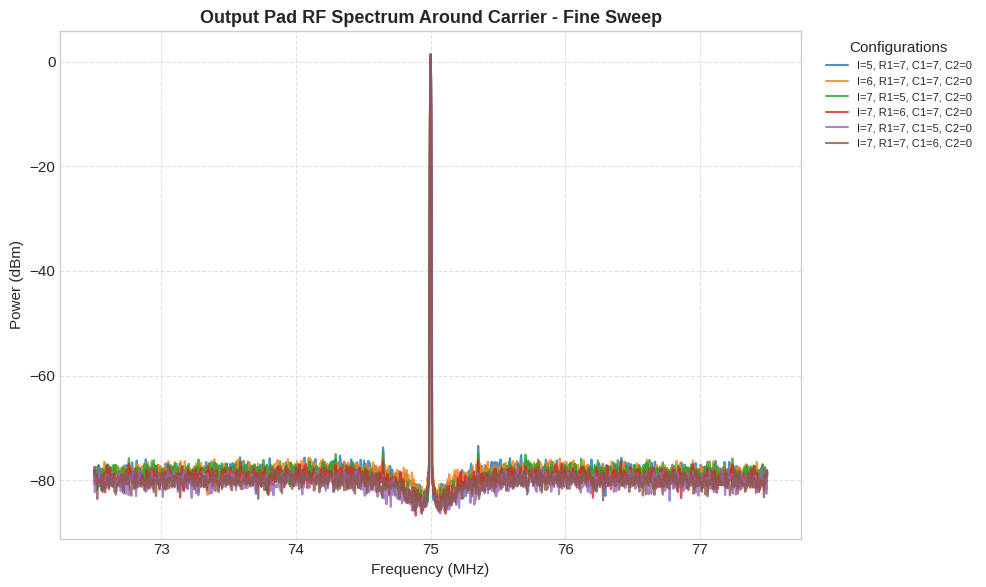

In [24]:
def plot_output_spectra(df_traces, top_n=6, title_suffix=""):
    if df_traces is None or df_traces.empty or "kind" not in df_traces.columns or "spectrum" not in df_traces["kind"].values:
        return
        
    sub = df_traces[df_traces["kind"] == "spectrum"]
    fig, ax = plt.subplots(figsize=(10, 6))
    
    for vals, grp in list(sub.groupby(["set_current", "set_r1", "set_c1", "set_c2"]))[:top_n]:
        lbl = f"I={int(vals[0])}, R1={int(vals[1])}, C1={int(vals[2])}, C2={int(vals[3])}"
        grp_s = grp.sort_values("freq")
        ax.plot(grp_s["freq"] / 1e6, grp_s["level_dbm"], label=lbl, alpha=0.8)
        
    ax.set_xlabel("Frequency (MHz)", fontsize=11)
    ax.set_ylabel("Power (dBm)", fontsize=11)
    ax.set_title(f"Output Pad RF Spectrum Around Carrier{title_suffix}", fontsize=13, fontweight="bold")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Configurations", fontsize=8)
    plt.tight_layout()
    plt.show()

# Adaptive plotting: Coarse, Fine, or Both
both_active = show_coarse and show_fine and has_coarse and has_fine

if show_coarse and has_coarse:
    suffix = " - Coarse Sweep" if both_active else ""
    plot_output_spectra(traces_coarse, top_n=6, title_suffix=suffix)

if show_fine and has_fine:
    suffix = " - Fine Sweep" if both_active else ""
    plot_output_spectra(traces_fine, top_n=6, title_suffix=suffix)


### 10. Zoomed Reference Spur Spectra Around $\pm f_{\text{ref}}$
Plots the high-resolution narrow-span spectra captured around the upper sideband ($f_c + f_{\text{ref}}$) and lower sideband ($f_c - f_{\text{ref}}$), where the reference spur appears at an offset of $\pm 37.5\text{ MHz}$.

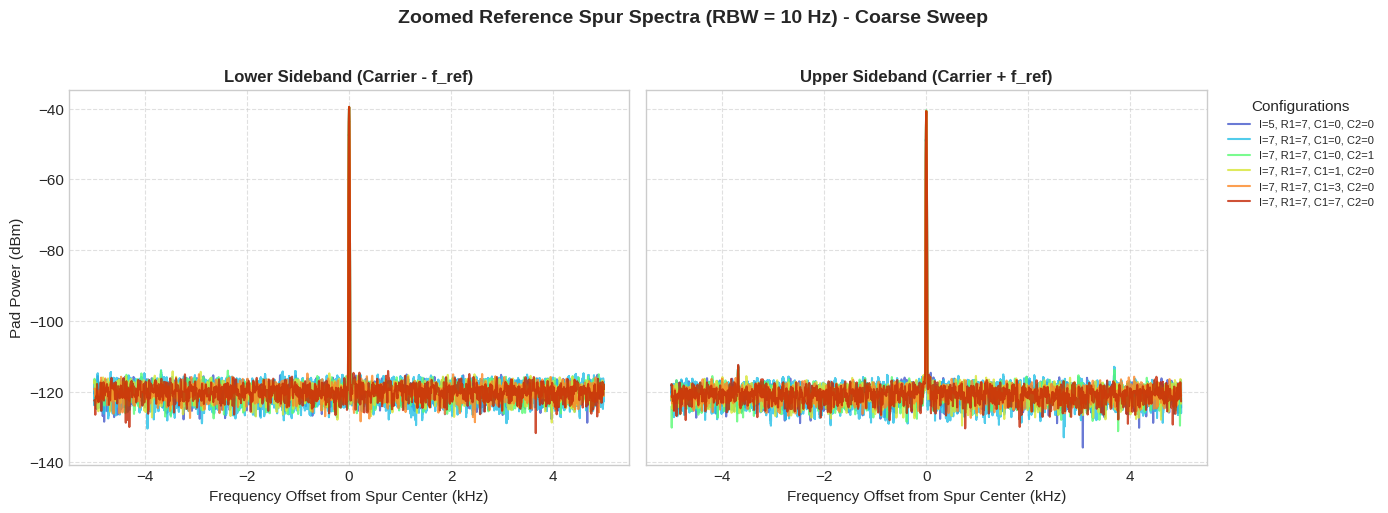

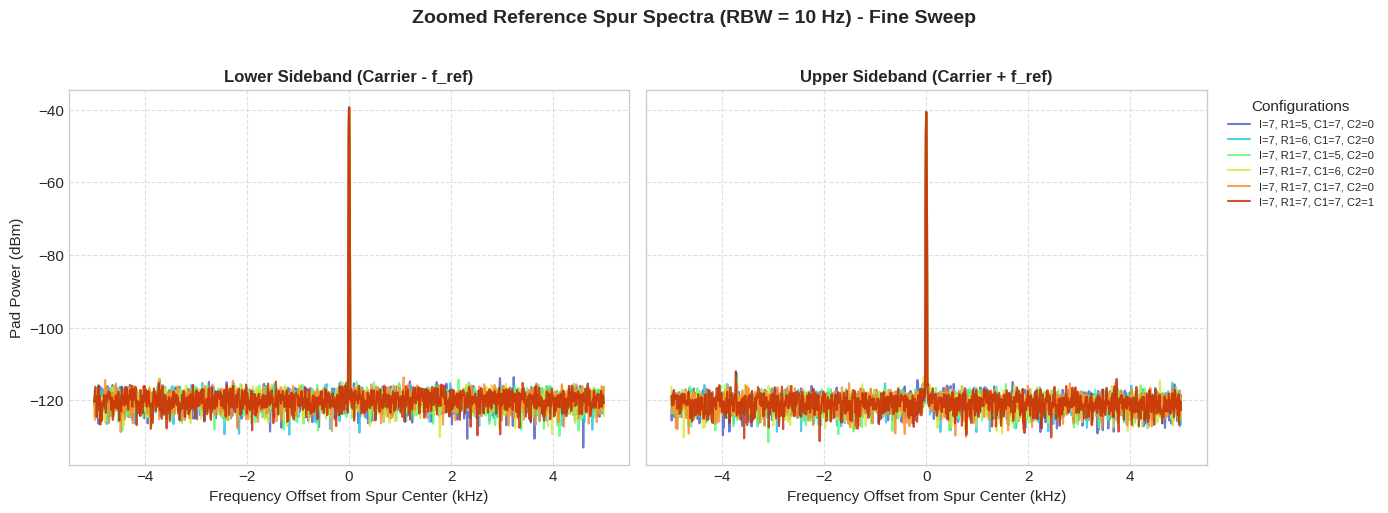

In [25]:
def plot_reference_spur_spectra(df_traces, df_results=None, top_n=6, sideband="both", title_suffix=""):
    if df_traces is None or df_traces.empty or "kind" not in df_traces.columns or "ref_spur" not in df_traces["kind"].values:
        return

    sub = df_traces[df_traces["kind"] == "ref_spur"].copy()
    if df_results is not None:
        jit_sort = "time_jitter_pnm_ps" if ("time_jitter_pnm_ps" in df_results.columns and df_results["time_jitter_pnm_ps"].notna().any()) else "time_jitter_trace_ps"
        best_labels = list(df_results.sort_values(jit_sort)["config_label"].unique()[:top_n])
    else:
        best_labels = None

    group_cols = ["set_current", "set_r1", "set_c1", "set_c2"]
    groups = list(sub.groupby(group_cols))
    if best_labels is not None:
        groups = [(vals, grp) for vals, grp in groups if f"I={int(vals[0])}, R1={int(vals[1])}, C1={int(vals[2])}, C2={int(vals[3])}" in best_labels]
    groups = groups[:top_n]

    if not groups:
        return

    f_carrier = df_results["f_out_meas"].iloc[0] if df_results is not None and "f_out_meas" in df_results.columns else 75e6
    
    fig, (ax_l, ax_u) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
    colors = plt.cm.turbo(np.linspace(0.1, 0.9, len(groups)))

    for (vals, grp), color in zip(groups, colors):
        lbl = f"I={int(vals[0])}, R1={int(vals[1])}, C1={int(vals[2])}, C2={int(vals[3])}"
        centers = grp["center"].unique()
        for c in centers:
            grp_c = grp[grp["center"] == c].sort_values("freq")
            target_ax = ax_u if c > f_carrier else ax_l
            offset_khz = (grp_c["freq"] - c) / 1e3
            target_ax.plot(offset_khz, grp_c["level_dbm"], label=lbl, color=color, linewidth=1.5, alpha=0.8)

    ax_l.set_title("Lower Sideband (Carrier - f_ref)", fontweight="bold", fontsize=12)
    ax_l.set_xlabel("Frequency Offset from Spur Center (kHz)", fontsize=11)
    ax_l.set_ylabel("Pad Power (dBm)", fontsize=11)
    ax_l.grid(True, linestyle="--", alpha=0.6)

    ax_u.set_title("Upper Sideband (Carrier + f_ref)", fontweight="bold", fontsize=12)
    ax_u.set_xlabel("Frequency Offset from Spur Center (kHz)", fontsize=11)
    ax_u.grid(True, linestyle="--", alpha=0.6)
    ax_u.legend(bbox_to_anchor=(1.02, 1), loc="upper left", title="Configurations", fontsize=8)

    plt.suptitle(f"Zoomed Reference Spur Spectra (RBW = 10 Hz){title_suffix}", fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

# Adaptive plotting: Coarse, Fine, or Both
both_active = show_coarse and show_fine and has_coarse and has_fine

if show_coarse and has_coarse:
    suffix = " - Coarse Sweep" if both_active else ""
    plot_reference_spur_spectra(traces_coarse, df_coarse, top_n=6, title_suffix=suffix)

if show_fine and has_fine:
    suffix = " - Fine Sweep" if both_active else ""
    plot_reference_spur_spectra(traces_fine, df_fine, top_n=6, title_suffix=suffix)


### 11. Combined Multi-Frequency Comparison (4.8 GHz, 6 GHz, 7 GHz, 8 GHz)
Compares the optimal performance, loop filter settings, jitter scaling, reference spur suppression, and power consumption across all evaluated VCO operating frequencies.

In [26]:
def plot_multi_frequency_summary_table(runs_data, view_mode="auto"):
    """Compile and display multi-frequency benchmark tables adaptively for coarse and/or fine sweeps."""
    coarse_rows = []
    fine_rows = []
    comparison_rows = []
    
    for tf in sorted(runs_data.keys()):
        entry = runs_data[tf]
        f_ghz = tf / 1e9
        
        # Coarse summary
        c = entry.get("coarse")
        best_c = get_best_config(c["df"]) if c else {}
        if best_c:
            coarse_rows.append({
                "Frequency": f"{f_ghz:.1f} GHz",
                "Best Filter Config": best_c["label"],
                "PNM RMS Jitter (ps)": best_c["jitter_ps"],
                "Trace Jitter (ps)": best_c.get("trace_jitter_ps", float("nan")),
                "Noise Part (ps)": best_c.get("noise_ps", float("nan")),
                "Spur Part (ps)": best_c.get("spur_ps", float("nan")),
                "Pad Ref Spur (dBc)": best_c.get("ref_spur_dbc", float("nan")),
                "VCO Ref Spur (dBc)": best_c.get("ref_spur_vco_dbc", float("nan")),
                "Power (mW)": best_c.get("power_mw", float("nan")),
            })
            
        # Fine summary
        fn = entry.get("fine")
        best_fn = get_best_config(fn["df"]) if fn else {}
        if best_fn:
            fine_rows.append({
                "Frequency": f"{f_ghz:.1f} GHz",
                "Best Filter Config": best_fn["label"],
                "Total RMS Jitter (ps)": best_fn["jitter_ps"],
                "Noise Part (ps)": best_fn.get("noise_ps", float("nan")),
                "Spur Part (ps)": best_fn.get("spur_ps", float("nan")),
                "Pad Ref Spur (dBc)": best_fn.get("ref_spur_dbc", float("nan")),
                "VCO Ref Spur (dBc)": best_fn.get("ref_spur_vco_dbc", float("nan")),
                "Power (mW)": best_fn.get("power_mw", float("nan")),
            })
            
        # Comparison row if both exist
        if best_c and best_fn:
            delta_j = best_fn["jitter_ps"] - best_c["jitter_ps"]
            pct_j = (delta_j / best_c["jitter_ps"]) * 100.0
            comparison_rows.append({
                "Frequency": f"{f_ghz:.1f} GHz",
                "Best Coarse Config": best_c["label"],
                "Coarse PNM Jitter (ps)": best_c["jitter_ps"],
                "Best Fine Config": best_fn["label"],
                "Fine Jitter (ps)": best_fn["jitter_ps"],
                "Jitter Change (ps)": delta_j,
                "Improvement (%)": -pct_j,
            })

    mode = str(view_mode).lower().strip()
    show_c = mode in ("auto", "both", "coarse") and bool(coarse_rows)
    show_f = mode in ("auto", "both", "fine") and bool(fine_rows)

    if show_c:
        print("=" * 85)
        print("  MULTI-FREQUENCY BENCHMARK: COARSE SWEEPS SUMMARY")
        print("=" * 85)
        display(pd.DataFrame(coarse_rows).set_index("Frequency"))

    if show_f:
        print("\n" + "=" * 85)
        print("  MULTI-FREQUENCY BENCHMARK: FINE SWEEPS SUMMARY")
        print("=" * 85)
        display(pd.DataFrame(fine_rows).set_index("Frequency"))

    if comparison_rows and (mode in ("auto", "both")):
        print("\n" + "=" * 85)
        print("  DIRECT COMPARISON: COARSE VS FINE OPTIMAL JITTER IMPROVEMENT")
        print("=" * 85)
        display(pd.DataFrame(comparison_rows).set_index("Frequency"))

plot_multi_frequency_summary_table(runs_data, view_mode=SWEEP_TIER_VIEW)


  MULTI-FREQUENCY BENCHMARK: COARSE SWEEPS SUMMARY


,Best Filter Config,PNM RMS Jitter (ps),Trace Jitter (ps),Noise Part (ps),Spur Part (ps),Pad Ref Spur (dBc),VCO Ref Spur (dBc),Power (mW)
Frequency,,,,,,,,
4.8 GHz,"I=7, R1=7, C1=7, C2=0",15.85,NaN,15.83,0.74,-40.97,-4.85,0.99
6.0 GHz,"I=7, R1=7, C1=7, C2=0",29.55,NaN,29.55,0.00,-36.53,-0.41,1.22
7.0 GHz,"I=7, R1=7, C1=7, C2=0",23.08,NaN,23.08,0.00,-34.58,1.54,1.42
8.0 GHz,"I=7, R1=7, C1=7, C2=0",17.22,NaN,17.22,0.13,-32.56,3.56,1.63



  MULTI-FREQUENCY BENCHMARK: FINE SWEEPS SUMMARY


,Best Filter Config,Total RMS Jitter (ps),Noise Part (ps),Spur Part (ps),Pad Ref Spur (dBc),VCO Ref Spur (dBc),Power (mW)
Frequency,,,,,,,
4.8 GHz,"I=7, R1=6, C1=7, C2=0",16.16,16.15,0.73,-40.80,-4.68,0.98
6.0 GHz,"I=7, R1=7, C1=7, C2=0",51.05,51.05,0.00,-36.37,-0.25,1.21
7.0 GHz,"I=7, R1=5, C1=7, C2=0",22.32,22.32,0.00,-34.52,1.61,1.41
8.0 GHz,"I=7, R1=5, C1=7, C2=0",16.71,16.71,0.13,-32.50,3.63,1.62



  DIRECT COMPARISON: COARSE VS FINE OPTIMAL JITTER IMPROVEMENT


,Best Coarse Config,Coarse PNM Jitter (ps),Best Fine Config,Fine Jitter (ps),Jitter Change (ps),Improvement (%)
Frequency,,,,,,
4.8 GHz,"I=7, R1=7, C1=7, C2=0",15.85,"I=7, R1=6, C1=7, C2=0",16.16,0.31,-1.99
6.0 GHz,"I=7, R1=7, C1=7, C2=0",29.55,"I=7, R1=7, C1=7, C2=0",51.05,21.49,-72.73
7.0 GHz,"I=7, R1=7, C1=7, C2=0",23.08,"I=7, R1=5, C1=7, C2=0",22.32,-0.76,3.29
8.0 GHz,"I=7, R1=7, C1=7, C2=0",17.22,"I=7, R1=5, C1=7, C2=0",16.71,-0.50,2.92


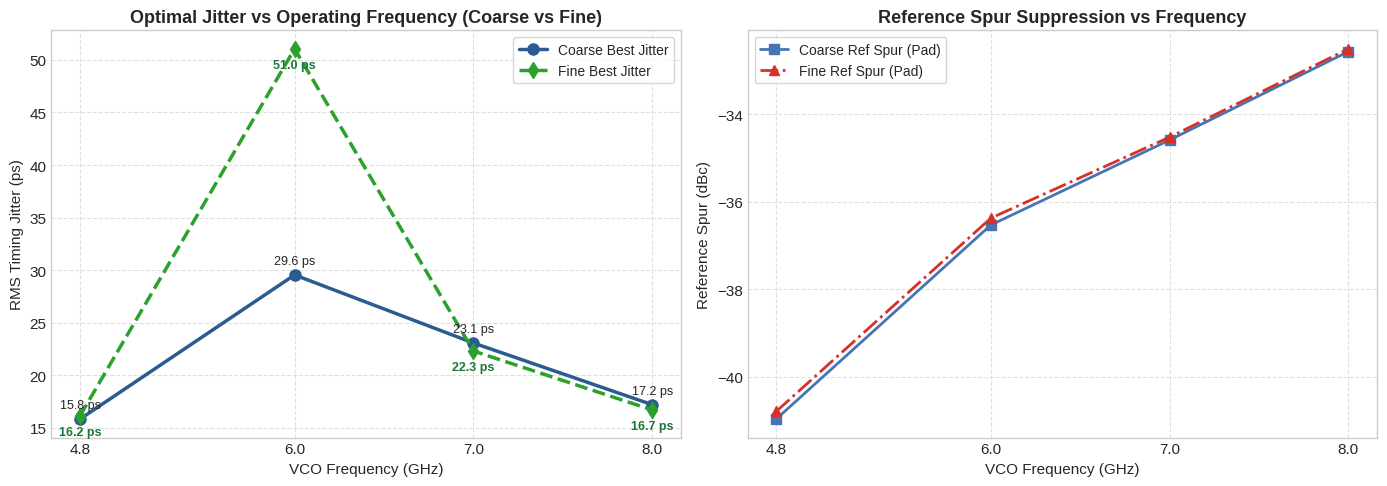

In [27]:
def plot_multi_frequency_trends(runs_data, view_mode="auto"):
    """Plot Jitter scaling and Reference Spur suppression vs Operating Frequency adaptively."""
    freqs_c, total_jc, noise_jc, spur_jc, ref_spur_c = [], [], [], [], []
    freqs_f, total_jf, noise_jf, spur_jf, ref_spur_f = [], [], [], [], []
    
    for tf in sorted(runs_data.keys()):
        entry = runs_data[tf]
        f_ghz = tf / 1e9
        
        c = entry.get("coarse")
        if c and not c["df"].empty:
            best_c = get_best_config(c["df"])
            if best_c:
                freqs_c.append(f_ghz)
                total_jc.append(best_c["jitter_ps"])
                noise_jc.append(best_c["noise_ps"])
                spur_jc.append(best_c["spur_ps"])
                ref_spur_c.append(best_c["ref_spur_dbc"])
                
        fn = entry.get("fine")
        if fn and not fn["df"].empty:
            best_f = get_best_config(fn["df"])
            if best_f:
                freqs_f.append(f_ghz)
                total_jf.append(best_f["jitter_ps"])
                noise_jf.append(best_f["noise_ps"])
                spur_jf.append(best_f["spur_ps"])
                ref_spur_f.append(best_f["ref_spur_dbc"])
                
    mode = str(view_mode).lower().strip()
    show_c = mode in ("auto", "both", "coarse") and bool(freqs_c)
    show_f = mode in ("auto", "both", "fine") and bool(freqs_f)

    if not show_c and not show_f:
        print("No multi-frequency data available to plot.")
        return
        
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    all_freqs = sorted(set(freqs_c + freqs_f))
    
    # 1. Jitter vs Frequency
    if show_c:
        lbl = "Coarse Best Jitter" if show_f else "Optimal RMS Jitter"
        ax1.plot(freqs_c, total_jc, "o-", color="#2b5c8f", linewidth=2.5, markersize=8, label=lbl)
        for f, j in zip(freqs_c, total_jc):
            ax1.annotate(f"{j:.1f} ps", (f, j), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
            
    if show_f:
        lbl = "Fine Best Jitter" if show_c else "Optimal RMS Jitter"
        ax1.plot(freqs_f, total_jf, "d--", color="#2ca02c", linewidth=2.5, markersize=8, label=lbl)
        for f, j in zip(freqs_f, total_jf):
            ax1.annotate(f"{j:.1f} ps", (f, j), textcoords="offset points", xytext=(0, -14), ha="center", color="#1b7837", fontweight="bold", fontsize=9)
            
    ax1.set_xlabel("VCO Frequency (GHz)", fontsize=11)
    ax1.set_ylabel("RMS Timing Jitter (ps)", fontsize=11)
    title_tag = " (Coarse vs Fine)" if (show_c and show_f) else ("")
    ax1.set_title(f"Optimal Jitter vs Operating Frequency{title_tag}", fontweight="bold", fontsize=13)
    ax1.set_xticks(all_freqs)
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.legend(frameon=True, fontsize=10)
    
    # 2. Reference Spur vs Frequency
    has_valid_spur_c = show_c and any(not np.isnan(v) for v in ref_spur_c)
    has_valid_spur_f = show_f and any(not np.isnan(v) for v in ref_spur_f)
    
    if has_valid_spur_c or has_valid_spur_f:
        if has_valid_spur_c:
            lbl = "Coarse Ref Spur (Pad)" if show_f else "Ref Spur (Pad)"
            ax2.plot(freqs_c, ref_spur_c, "s-", color="#4575b4", linewidth=2, markersize=7, label=lbl)
        if has_valid_spur_f:
            lbl = "Fine Ref Spur (Pad)" if show_c else "Ref Spur (Pad)"
            ax2.plot(freqs_f, ref_spur_f, "^-.", color="#d73027", linewidth=2, markersize=7, label=lbl)
        ax2.set_xlabel("VCO Frequency (GHz)", fontsize=11)
        ax2.set_ylabel("Reference Spur (dBc)", fontsize=11)
        ax2.set_title("Reference Spur Suppression vs Frequency", fontweight="bold", fontsize=13)
        ax2.set_xticks(all_freqs)
        ax2.grid(True, linestyle="--", alpha=0.6)
        ax2.legend(frameon=True, fontsize=10)
    else:
        ax2.text(0.5, 0.5, "Reference spur data not available for plotting.", ha="center", va="center", transform=ax2.transAxes)
        
    plt.tight_layout()
    plt.show()

plot_multi_frequency_trends(runs_data, view_mode=SWEEP_TIER_VIEW)


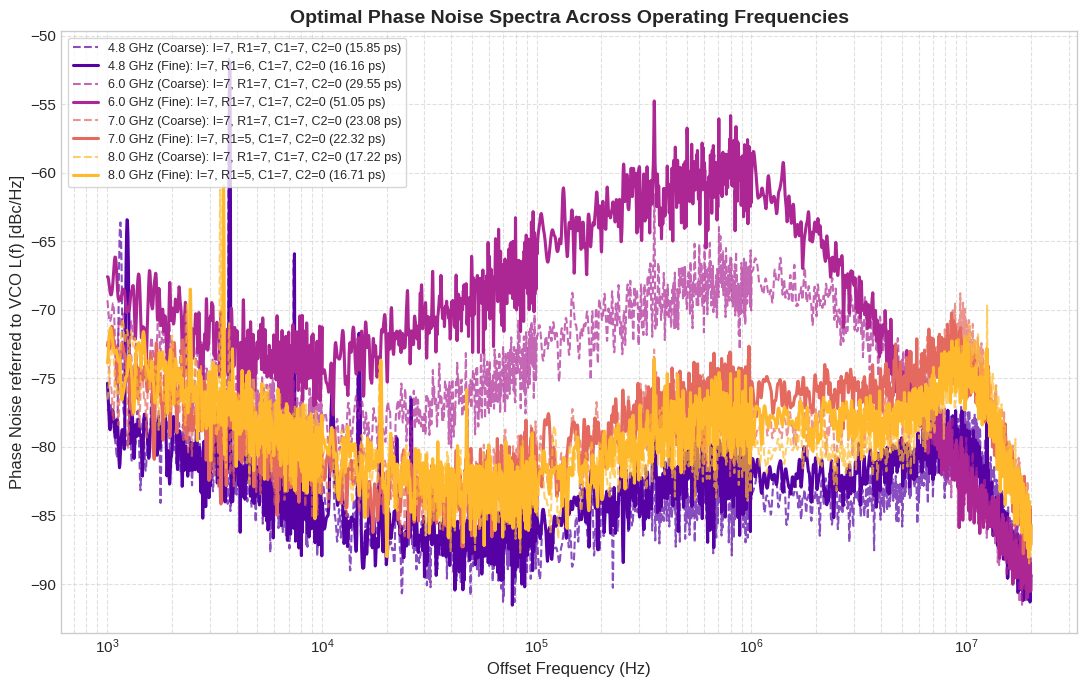

In [28]:
def plot_multi_frequency_phase_noise_overlay(runs_data, ref_to_vco=True, view_mode="auto"):
    """Overlay optimal Phase Noise spectra L(f) across frequencies adaptively for coarse and/or fine sweeps."""
    mode = str(view_mode).lower().strip()
    fig, ax = plt.subplots(figsize=(11, 7))
    colors = plt.cm.plasma(np.linspace(0.15, 0.85, len(runs_data)))
    plotted = 0
    
    for (tf, entry), color in zip(sorted(runs_data.items()), colors):
        f_ghz = tf / 1e9
        tiers_to_plot = []
        if mode in ("auto", "both", "coarse") and entry.get("coarse"):
            tiers_to_plot.append(("Coarse", entry["coarse"], "--", 1.5, 0.7))
        if mode in ("auto", "both", "fine") and entry.get("fine"):
            tiers_to_plot.append(("Fine", entry["fine"], "-", 2.2, 1.0))
            
        for tier_name, tier_entry, ls, lw, alpha in tiers_to_plot:
            df = tier_entry.get("df")
            traces = tier_entry.get("traces")
            if traces is None or traces.empty or "kind" not in traces.columns:
                continue
            if "L_trace" not in traces["kind"].values:
                continue
                
            best = get_best_config(df)
            if not best:
                continue
                
            sub = traces[traces["kind"] == "L_trace"].copy()
            match = sub[
                (sub["set_current"] == best["I"]) &
                (sub["set_r1"] == best["R1"]) &
                (sub["set_c1"] == best["C1"]) &
                (sub["set_c2"] == best["C2"])
            ]
            if match.empty:
                continue
                
            match_sorted = match.sort_values("freq")
            div_db = 20 * math.log10(best["row"].get("total_div", 64)) if ref_to_vco else 0.0
            y_vals = match_sorted["level_dbm"] + div_db
            
            tier_label = f" ({tier_name})" if len(tiers_to_plot) > 1 else ""
            tag = " PNM" if ("pnm_jitter_ps" in best and not math.isnan(best["pnm_jitter_ps"])) else ""
            lbl = f"{f_ghz:.1f} GHz{tier_label}: {best['label']} ({best['jitter_ps']:.2f} ps{tag})"
            ax.plot(match_sorted["freq"], y_vals, label=lbl, color=color, linestyle=ls, linewidth=lw, alpha=alpha)
            plotted += 1
            
    if plotted == 0:
        print("No L_trace data available across locked runs to overlay.")
        plt.close(fig)
        return
        
    ax.set_xscale("log")
    ax.set_xlabel("Offset Frequency (Hz)", fontsize=12)
    ylabel = "Phase Noise referred to VCO L(f) [dBc/Hz]" if ref_to_vco else "Phase Noise on Pad L(f) [dBc/Hz]"
    ax.set_ylabel(ylabel, fontsize=12)
    ax.set_title("Optimal Phase Noise Spectra Across Operating Frequencies", fontsize=14, fontweight="bold")
    ax.grid(True, which="both", linestyle="--", alpha=0.6)
    ax.legend(frameon=True, fontsize=9)
    plt.tight_layout()
    plt.show()

plot_multi_frequency_phase_noise_overlay(runs_data, ref_to_vco=True, view_mode=SWEEP_TIER_VIEW)
